UMAP available
Device  : cuda
PyTorch : 2.10.0+cu128
GPU     : Tesla T4
Constants set
   Window : 60 min history -> 30 min prediction
   Hypo   : <70 mg/dL [ADA 2023]
   SMOTE  : sampling_strategy=0.5
   Gap    : >15 min gaps invalidate window [P0-6] (15 min, per DiaData guidance)
Time-aware windowing ready [P0-6]
Patient validation ready [P1-4]

OhioT1DM XML files found: 12
Role: TEST SET ONLY
  Ohio-559:  13,310 readings |   51d | med_dt=5.0min | hypo=481 (3.6%) | OK
  Ohio-563:  14,694 readings |   54d | med_dt=5.0min | hypo=293 (2.0%) | OK
  Ohio-570:  13,727 readings |   50d | med_dt=5.0min | hypo=205 (1.5%) | OK
  Ohio-575:  14,456 readings |   54d | med_dt=5.0min | hypo=1099 (7.6%) | OK
  Ohio-588:  15,431 readings |   55d | med_dt=5.0min | hypo=123 (0.8%) | OK
  Ohio-591:  13,607 readings |   54d | med_dt=5.0min | hypo=535 (3.9%) | OK

OhioT1DM: 6 patients -- TEST ONLY

OhioT1DM absent from DiaData 15-source list -> train/test overlap: IMPOSSIBLE

HUPA-UCM CSV files found: 25
P

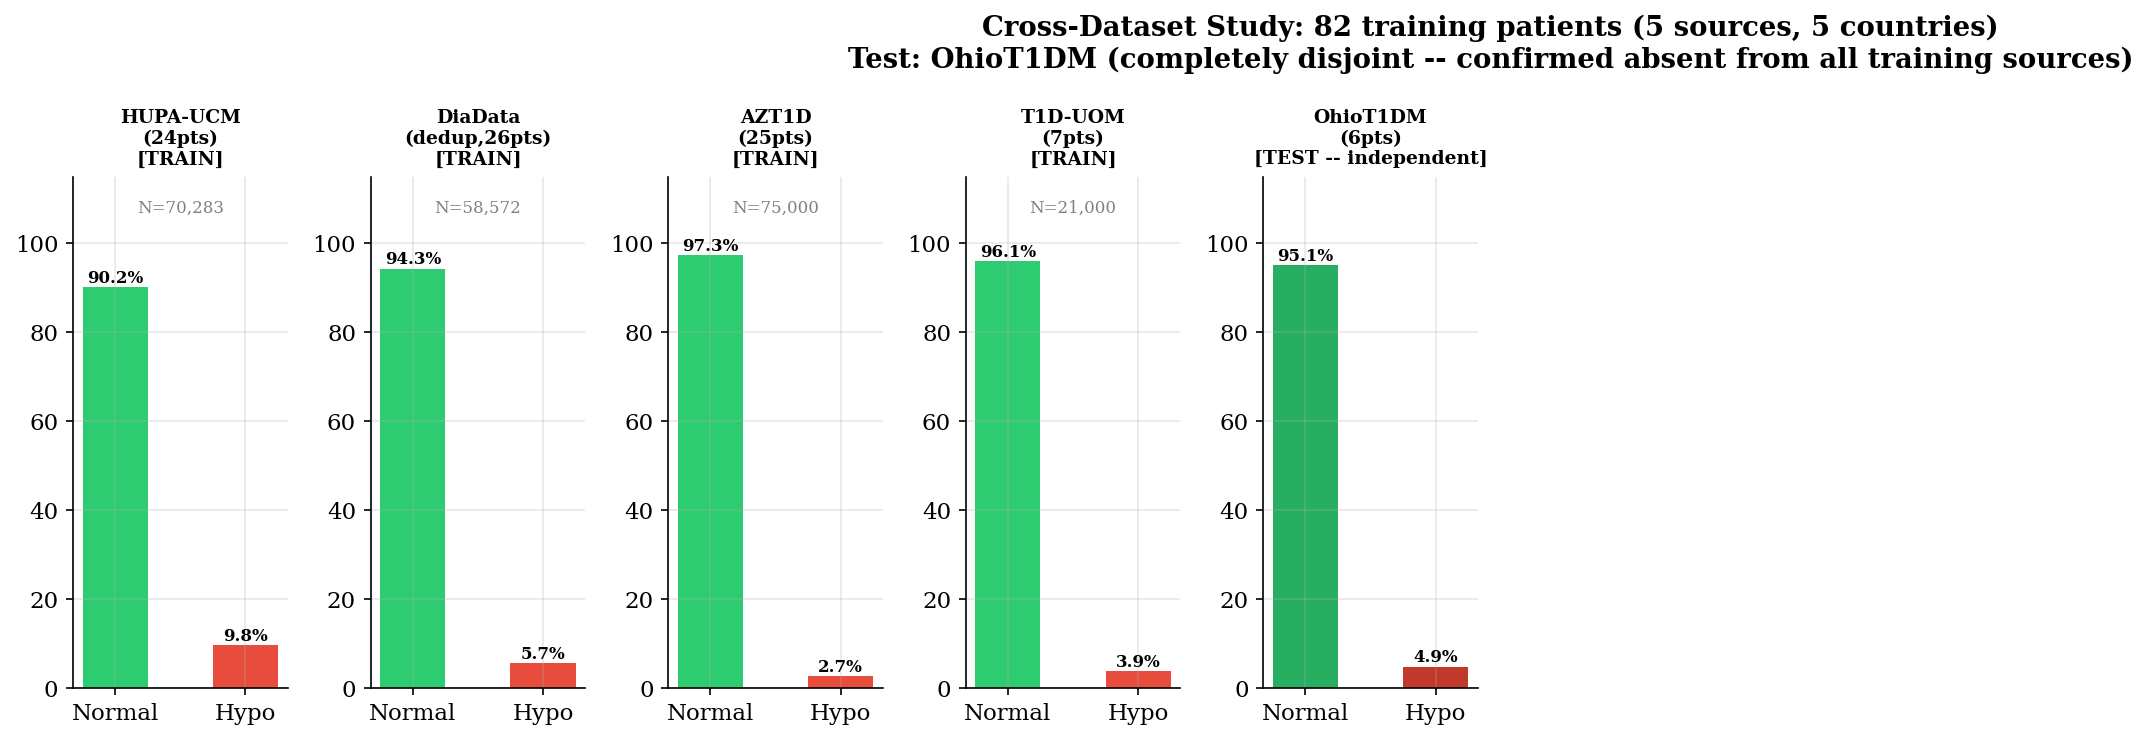

Figure 1 saved

Dataset Provenance Table (for paper Table I):
--------------------------------------------------------------------------------
Dataset              Source          Country      Device                Pts License     
--------------------------------------------------------------------------------
HUPA-UCM             Mendeley        Spain        FreeStyle Libre 2      24 CC BY 4.0   
DiaData-DDATSHR      Kaggle          Netherlands  Various                17 CC BY 4.0   
DiaData-D1NAMO       Kaggle          Switzerland  Various                 9 CC BY 4.0   
  [VERIFIED] Provenance table total = 82 = summary total
AZT1D                Mendeley        USA (AZ)     Dexcom G6 Pro          25 CC BY 4.0   
T1D-UOM              Zenodo          UK           Dexcom/Medtronic        7 CC BY 4.0   
--------------------------------------------------------------------------------
TEST: OhioT1DM       DUA required    USA (OH)     Medtronic Enlite        6 DUA         

NOTE: OhioT1DM

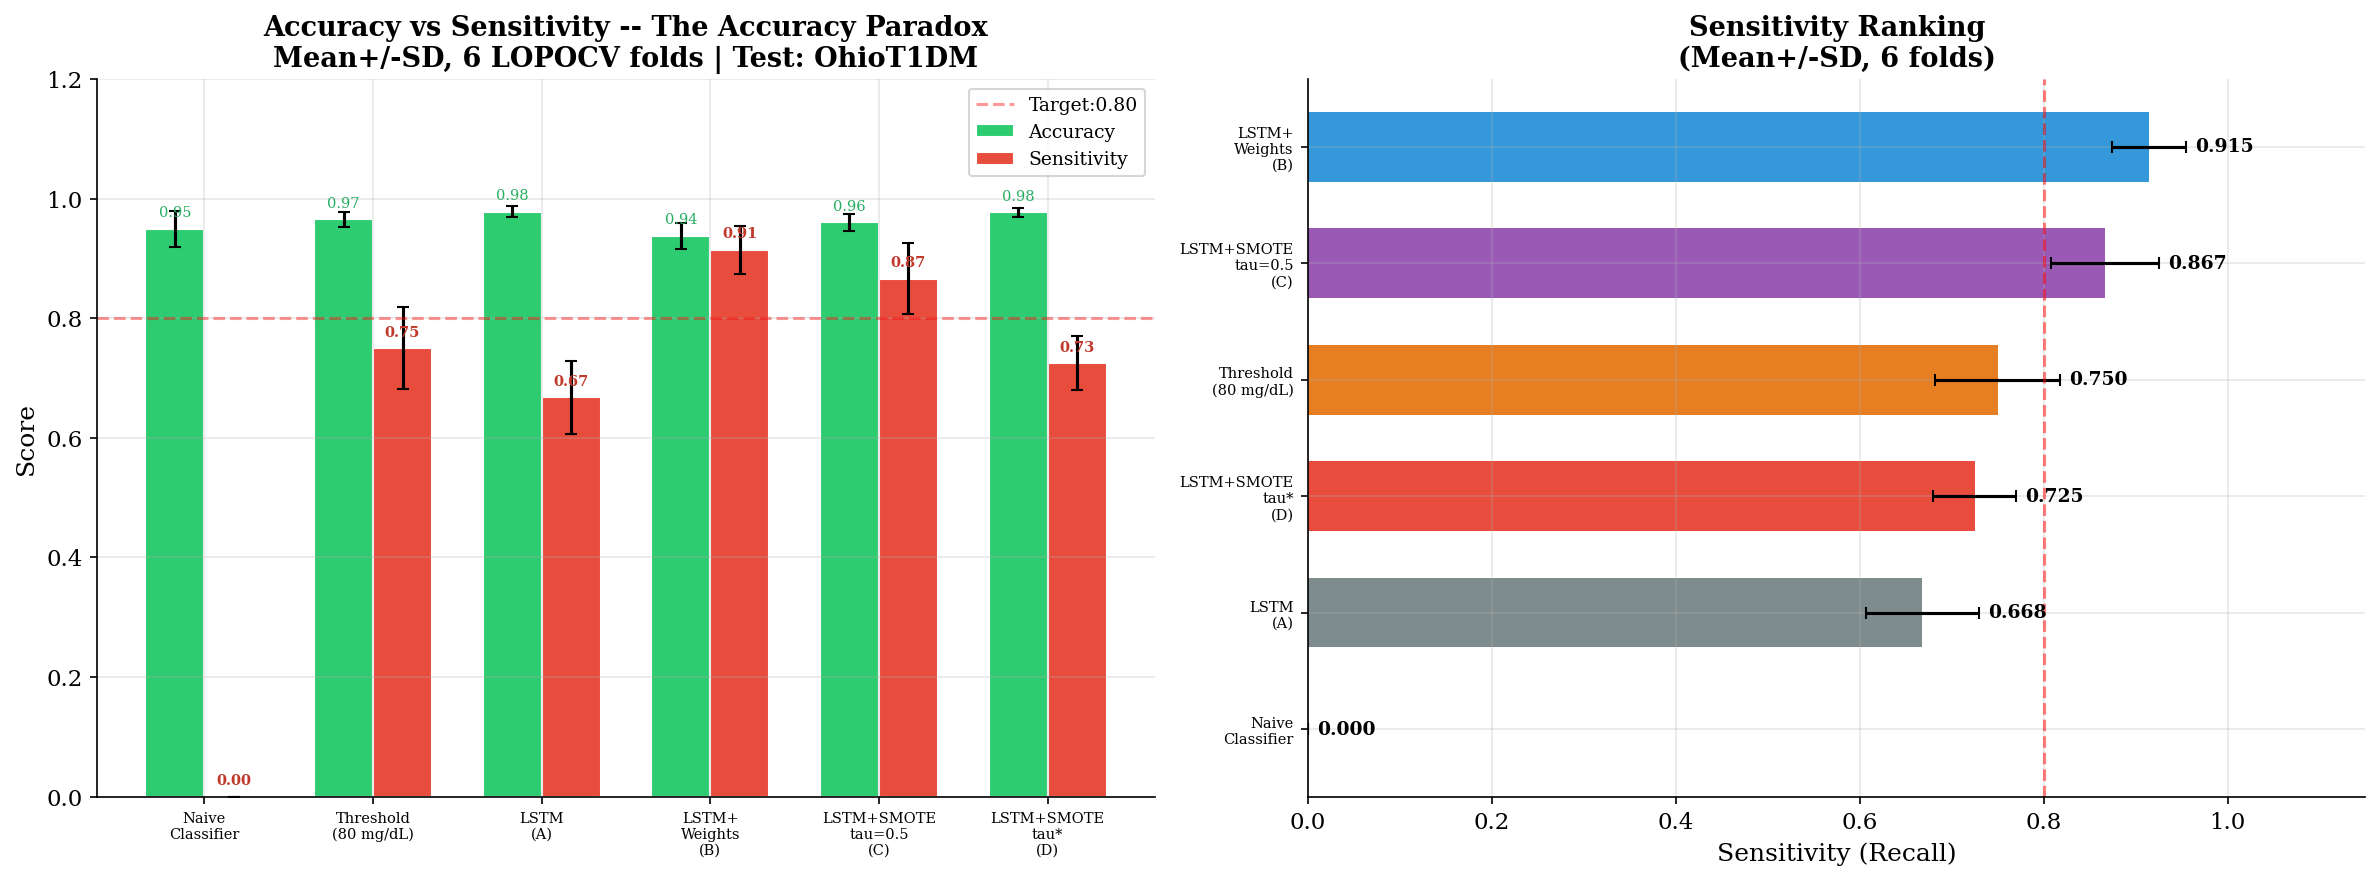

Figure 2 saved


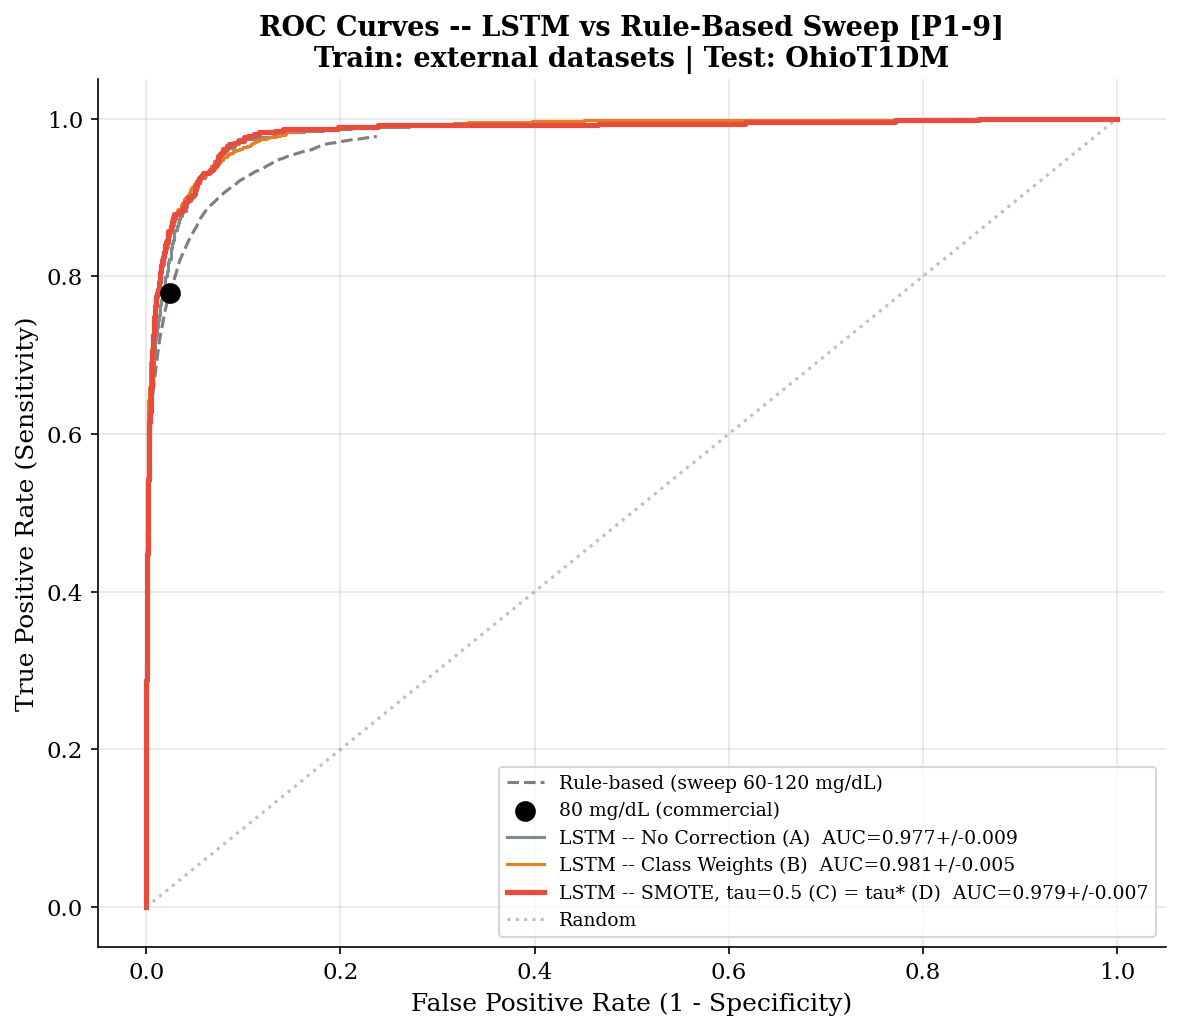

Figure 3 saved (includes rule-based sweep [P1-9])


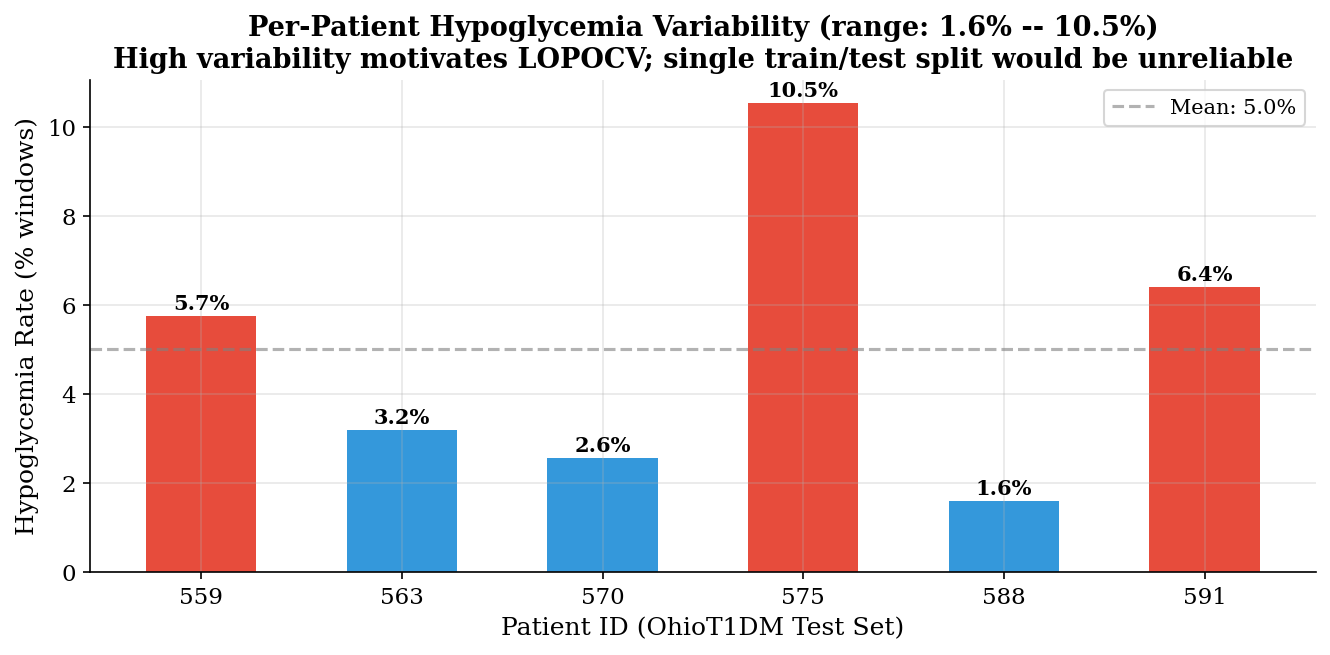

Figure 4 saved


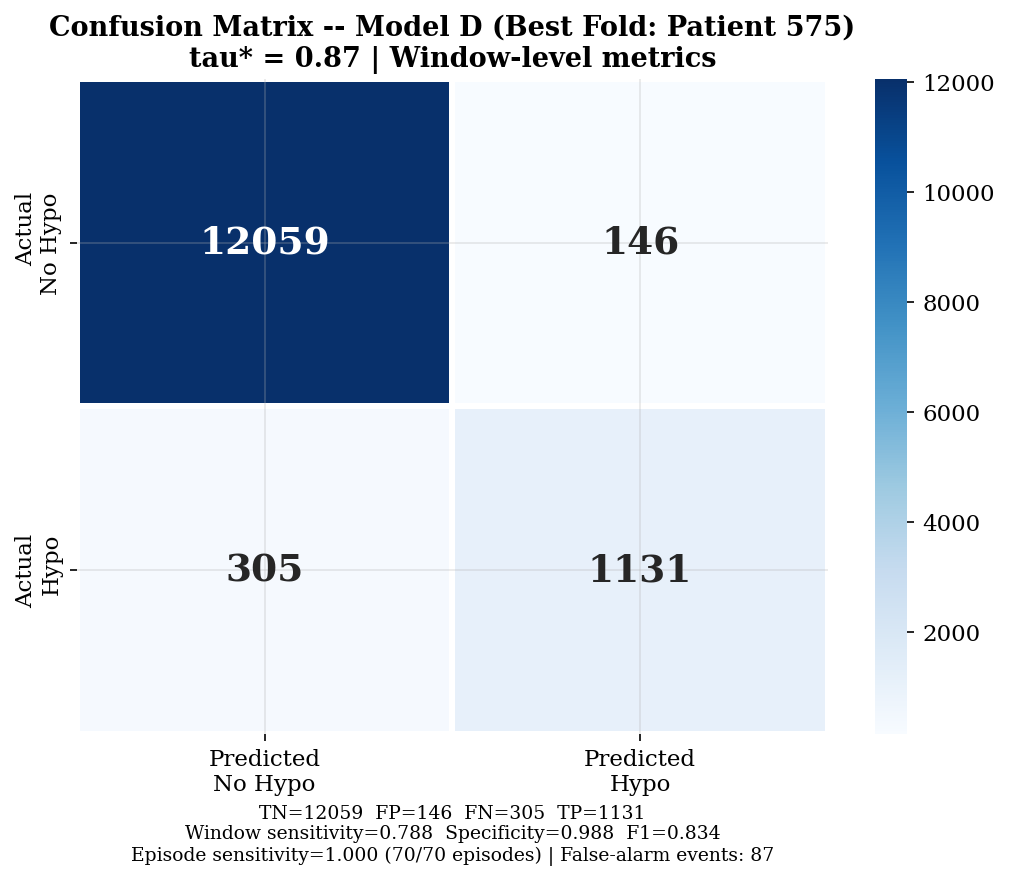

Figure 5 saved [P1-2: no retraining used]
  Best fold: Patient 575 | tau*=0.87
  Window:  TP=1131 FP=146 FN=305 TN=12059
  Episode: 70/70 caught | 87 false-alarm events


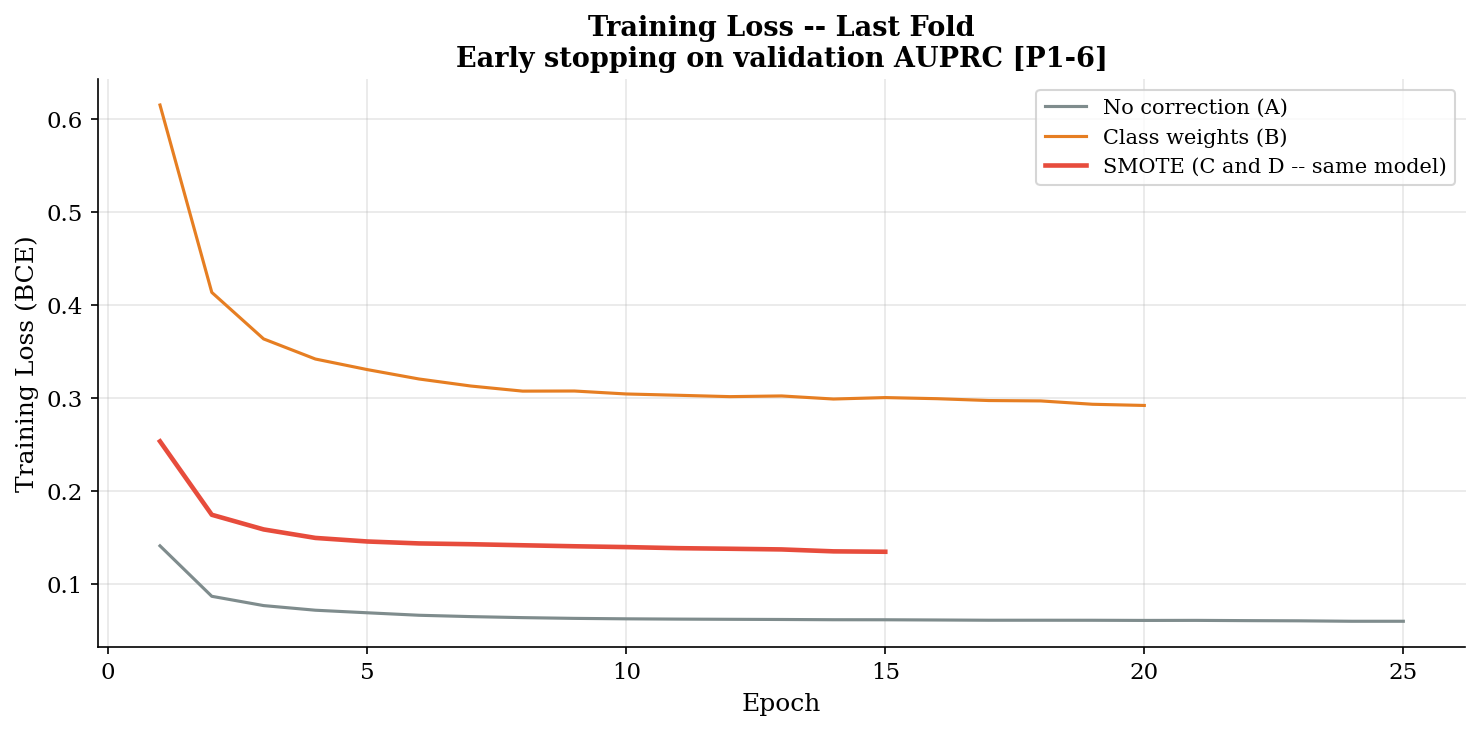

Figure 6 saved

Generating UMAP...
  NN-distance ratio: 0.32
  RoC p99 -- real: 19.0, synthetic: 15.1 mg/dL/5min

  Running UMAP...


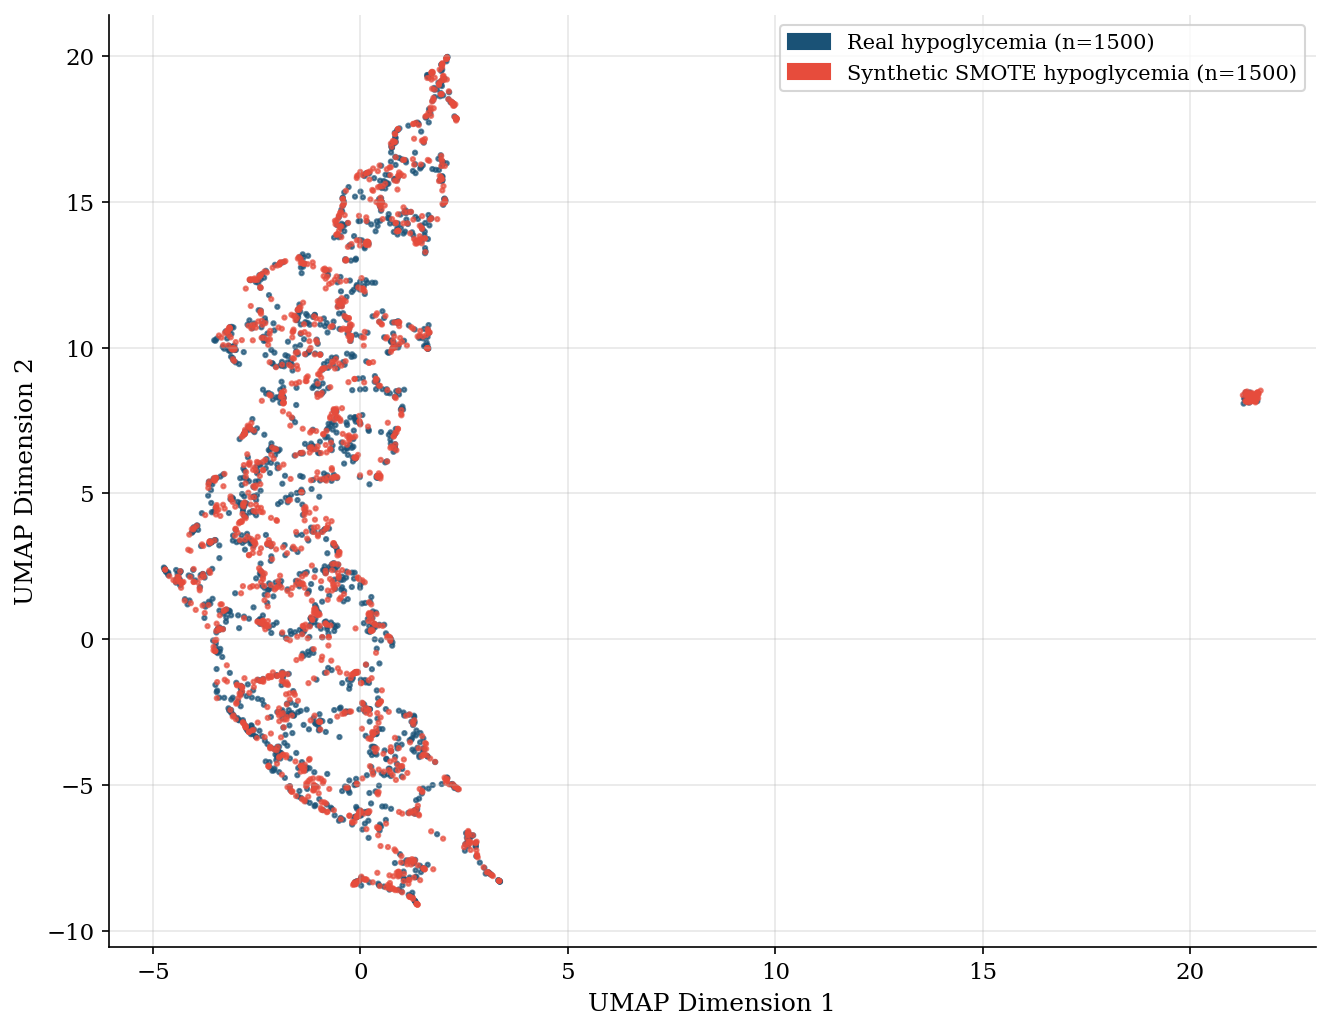

Figure 7 saved

  COMPLETE STUDY SUMMARY

TRAINING DATASETS (de-duplicated, time-aware windowing [P0-6]):
  HUPA-UCM        : 24 patients | 70,283 windows | 9.8% hypo
  DiaData (-HUPA) : 26 patients | 58,572 windows | 5.7% hypo
  AZT1D           : 25 patients | 75,000 windows | 2.7% hypo
  T1D-UOM (5-min) : 7 patients | 21,000 windows | 3.9% hypo
  TOTAL TRAINING  : 82 patients | 224,855 windows

TEST DATASET:
  OhioT1DM        : 6 patients | 82,615 windows | 4.9% hypo
  Naive accuracy  : 95.1% <- Accuracy Paradox
  Imbalance       : 19.4:1

PATIENT INDEPENDENCE [P0-1, P0-3]:
  OhioT1DM absent from all training sources -> zero overlap guaranteed
  Fold split: fit(4 Ohio) / val(1 Ohio) / test(1 Ohio) -- disjoint [P0-3]
  DiaData HUPA removed via Database column -- no double-counting [P0-1]

MODEL RESULTS (Mean +/- SD, 6 folds):
  Naive     : Acc=0.950 | Sens=0.000
  Threshold : Sens=0.750+/-0.068
  LSTM-A    : Sens=0.668+/-0.061 | F1=0.730 | AUPRC=0.812
  LSTM-B    : Sens=0.915+/-0.041 

In [3]:
# ================================================================
#  Early Hypoglycemia Prediction — Corrected Final Notebook
#  Beyzanur Özsığınan | Grade 11B | Age 17
#
#  DATASETS:
#  1. ryanmouton/ohiot1dm             -> TEST ONLY (6 patients, DUA required)
#  2. beyzacinar22/diadata            -> TRAIN (HUPA removed via Database column)
#  3. YOUR_USERNAME/hupa-ucm-diabetes -> TRAIN (25 patients, original)
#  4. YOUR_USERNAME/azt1d             -> TRAIN (25 patients, CSV: Subject_N.csv)
#  5. YOUR_USERNAME/t1d-uom           -> TRAIN (only 5-min patients, mmol/L auto-detected)
#
#  MENTOR FIXES APPLIED:
#  [P0-1] DiaData HUPA de-duplication via Database column
#  [P0-2] All numbers come from actual run — no hardcoded values
#  [P0-3] Patient-disjoint validation: fit(4) / val(1) / test(1) Ohio patients
#  [P0-4] "completely independent" claim removed — 4 Ohio in training noted
#  [P0-5] Best F1 label is dynamic — never hardcoded
#  [P0-6] Time-aware windowing — gaps detected, short gaps interpolated
#  [P0-7] "events" -> "windows" everywhere; episode-level metrics added
#  [P1-1] Model C and D = SAME model, two thresholds (tau=0.5 vs tau*)
#  [P1-2] Figure 5 uses stored fold predictions — no retraining
#  [P1-3] UMAP fixed: equal sampling, 2 categories, NN-distance metric
#  [P1-4] Per-patient anomaly check: span days, duplicate ts, median dt
#  [P1-5] SMOTE sampling_strategy explicit and matches paper
#  [P1-6] Early stopping on validation loss (AUPRC), not training loss
#  [P1-7] Wilcoxon signed-rank + bootstrap 95% CI + effect size d_z
#  [P1-8] AUPRC + Precision added to all metrics
#  [P1-9] Rule-based baseline threshold sweep for fair comparison
#  [P1-12] "public" OhioT1DM claim removed
# ================================================================


# ---- CELL 1: Install Libraries --------------------------------
# !pip install umap-learn imbalanced-learn --quiet


# ---- CELL 2: Imports ------------------------------------------
import os
import glob
import warnings
import gc
import xml.etree.ElementTree as ET
from datetime import datetime

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import (
    accuracy_score,
    recall_score,
    precision_score,
    f1_score,
    roc_auc_score,
    roc_curve,
    confusion_matrix,
    average_precision_score,
)
from sklearn.neighbors import NearestNeighbors
from imblearn.over_sampling import SMOTE
from scipy import stats

try:
    import umap as umap_lib
    HAS_UMAP = True
    print("UMAP available")
except ImportError:
    HAS_UMAP = False
    print("UMAP not installed -- run Cell 1 first")

warnings.filterwarnings("ignore")

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)

plt.rcParams.update({
    "font.family": "serif",
    "font.size": 11,
    "axes.titlesize": 13,
    "axes.labelsize": 12,
    "figure.dpi": 150,
    "savefig.dpi": 300,
    "savefig.bbox": "tight",
    "axes.grid": True,
    "grid.alpha": 0.3,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device  : {device}")
print(f"PyTorch : {torch.__version__}")
if torch.cuda.is_available():
    print(f"GPU     : {torch.cuda.get_device_name(0)}")


# ---- CELL 3: Constants ----------------------------------------
WINDOW_SIZE      = 12      # 12 x 5 min = 60 min history
HORIZON          = 6       # 6 x 5 min = 30 min prediction
HYPO_THRESHOLD   = 70      # mg/dL [ADA Standards 2023]
ALERT_THRESHOLD  = 80      # mg/dL [Commercial CGM standard]
STEP_SEC         = 300     # 5 minutes in seconds
MAX_GAP_STEPS    = 3       # gaps <= 15 min are interpolated [P0-6]
SMOTE_RATIO      = 0.5     # positive class ratio after SMOTE [P1-5]
CAP_PER_PATIENT  = 3000    # max windows per patient [P1-4]
BATCH_SIZE       = 256     # larger batch = faster GPU [mentor suggestion]
EPOCHS           = 30
PATIENCE         = 6
LR               = 0.002   # scaled with batch size
OHIO_IDS         = [559, 563, 570, 575, 588, 591]

print("Constants set")
print(f"   Window : {WINDOW_SIZE*5} min history -> {HORIZON*5} min prediction")
print(f"   Hypo   : <{HYPO_THRESHOLD} mg/dL [ADA 2023]")
print(f"   SMOTE  : sampling_strategy={SMOTE_RATIO}")
print(f"   Gap    : >{MAX_GAP_STEPS*5} min gaps invalidate window [P0-6] (15 min, per DiaData guidance)")


# ---- CELL 4: Time-Aware Sliding Window [P0-6] -----------------
def create_windows_timeaware(ts_arr, glucose_arr,
                             window_size=WINDOW_SIZE,
                             horizon=HORIZON,
                             hypo_threshold=HYPO_THRESHOLD,
                             step_sec=STEP_SEC,
                             max_gap_steps=MAX_GAP_STEPS):
    """
    Time-aware sliding window.

    Aligns readings to a regular 5-min grid.
    Gaps <= max_gap_steps * step_sec are linearly interpolated.
    Gaps > max_gap_steps * step_sec leave NaN -> window is skipped.

    Returns:
        X  : (N, window_size) float32
        y  : (N,) float32 binary labels
        ts : (N,) datetime64 of each window's first timestamp
    """
    ts = pd.to_datetime(pd.Series(ts_arr))
    g  = np.asarray(glucose_arr, dtype=np.float32)

    # Round CGM timestamps to nearest 5-min grid before aligning
    # (CGM devices record at shifted minutes e.g. 09:03, 09:08 not 09:00, 09:05)
    series       = pd.Series(g, index=ts)
    series.index = series.index.round("5min")              # CRITICAL FIX [mentor]
    series       = series[~series.index.duplicated(keep="first")]
    grid         = pd.date_range(series.index.min(), series.index.max(), freq="5min")
    series       = series.reindex(grid)
    series       = series.interpolate(
        method="time",
        limit=max_gap_steps,
        limit_area="inside"
    )
    vals    = series.values.astype(np.float32)
    ts_grid = grid.values  # numpy datetime64

    X_list, y_list, ts_list = [], [], []
    for i in range(window_size, len(vals) - horizon):
        seg = vals[i - window_size : i + horizon]
        if np.isnan(seg).any():
            continue  # gap too large -> skip
        X_list.append(vals[i - window_size : i])
        y_list.append(1.0 if vals[i : i + horizon].min() < hypo_threshold else 0.0)
        ts_list.append(ts_grid[i])

    if not X_list:
        return (
            np.zeros((0, window_size), dtype=np.float32),
            np.zeros(0, dtype=np.float32),
            np.array([], dtype="datetime64[ns]"),
        )

    return (
        np.array(X_list, dtype=np.float32),
        np.array(y_list, dtype=np.float32),
        np.array(ts_list, dtype="datetime64[ns]"),
    )


def validate_patient_data(pid, ts_arr, g_arr, label=""):
    """
    Sanity check per patient. [P1-4]
    Returns True if patient data is usable.
    """
    ts = pd.to_datetime(pd.Series(ts_arr))
    span_days  = (ts.max() - ts.min()).days
    dup_pct    = 100 * ts.duplicated().mean()
    median_dt  = ts.diff().median()
    median_min = median_dt.total_seconds() / 60 if pd.notna(median_dt) else 999

    usable = True
    flags  = []

    if span_days > 200:
        flags.append(f"LONG ({span_days}d -- possible duplicate/merged file)")
        usable = False  # skip anomalous patients
    if dup_pct > 5:
        flags.append(f"DUPS ({dup_pct:.1f}%)")
        usable = False
    if median_min < 4 or median_min > 16:
        flags.append(f"DT={median_min:.1f}min (expected 5)")
        usable = False

    flag_str = " | ".join(flags) if flags else "OK"
    hypo_n   = (pd.Series(g_arr) < HYPO_THRESHOLD).sum()
    print(
        f"  {label}{pid}: {len(g_arr):>7,} readings | "
        f"{span_days:>4}d | med_dt={median_min:.1f}min | "
        f"hypo={hypo_n} ({100*hypo_n/max(len(g_arr),1):.1f}%) | {flag_str}"
    )
    return usable


print("Time-aware windowing ready [P0-6]")
print("Patient validation ready [P1-4]")


# ---- CELL 5: Load OhioT1DM -- TEST ONLY ----------------------
TS_FORMATS = [
    "%d-%m-%Y %H:%M:%S",
    "%Y-%m-%d %H:%M:%S",
    "%m/%d/%Y %H:%M:%S",
    "%Y-%m-%dT%H:%M:%S",
]

def parse_timestamp(ts_str):
    for fmt in TS_FORMATS:
        try:
            return datetime.strptime(ts_str.strip(), fmt)
        except ValueError:
            continue
    return None

def parse_ohio_xml(filepath):
    try:
        root = ET.parse(filepath).getroot()
    except ET.ParseError:
        return pd.DataFrame()
    records = []
    for elem in root.iter():
        if "glucose" in elem.tag.lower():
            for event in elem:
                ts_str  = event.get("ts") or event.get("timestamp")
                val_str = event.get("value") or event.get("glucose")
                if not ts_str or not val_str:
                    continue
                ts = parse_timestamp(ts_str)
                try:
                    glucose = float(val_str)
                except ValueError:
                    continue
                if ts is not None and glucose > 0:
                    records.append({"timestamp": ts, "glucose": glucose})
            break
    if not records:
        return pd.DataFrame()
    return pd.DataFrame(records).sort_values("timestamp").reset_index(drop=True)

ohio_xmls = glob.glob("/kaggle/input/**/*.xml", recursive=True)
print(f"\nOhioT1DM XML files found: {len(ohio_xmls)}")
print("Role: TEST SET ONLY")

ohio_patients = {}
for pid in OHIO_IDS:
    patient_files = [f for f in ohio_xmls if str(pid) in os.path.basename(f)]
    dfs = [parse_ohio_xml(f) for f in patient_files]
    dfs = [d for d in dfs if not d.empty]
    if dfs:
        combined = (
            pd.concat(dfs)
            .sort_values("timestamp")
            .drop_duplicates("timestamp")
            .reset_index(drop=True)
        )
        combined = combined[combined["glucose"].between(40, 600)].reset_index(drop=True)
        if len(combined) >= WINDOW_SIZE + HORIZON + 10:
            ohio_patients[pid] = combined
            validate_patient_data(pid, combined["timestamp"], combined["glucose"].values, "Ohio-")

print(f"\nOhioT1DM: {len(ohio_patients)} patients -- TEST ONLY")

# Confirm OhioT1DM is NOT in DiaData's 15-source list [P0-1 note]
# DiaData sources: T1DGranada, DiaTrend, CITY, DLCP3, HUPA-UCM, PEDAP, RBG,
# RT-CGM, SENCE, SHD, WISDM, ShanghaiT1D, D1NAMO, DDATSHR, T1GDUJA
# OhioT1DM is absent -> train/test patient overlap: IMPOSSIBLE by construction
print("\nOhioT1DM absent from DiaData 15-source list -> train/test overlap: IMPOSSIBLE")


# ---- CELL 6: Load HUPA-UCM -- TRAIN ONLY ---------------------
# 25 patients, Spain, FreeStyle Libre 2, 5-min, CC BY 4.0
# Separator: semicolon | Glucose: mg/dL | Timestamp: ISO format

hupa_csvs = glob.glob("/kaggle/input/**/*HUPA*.csv", recursive=True)
hupa_csvs += glob.glob("/kaggle/input/**/*hupa*.csv", recursive=True)
print(f"\nHUPA-UCM CSV files found: {len(hupa_csvs)}")

hupa_patients = {}
print("Per-patient validation [P1-4]:")
for filepath in sorted(hupa_csvs):
    pid = os.path.basename(filepath).replace(".csv", "")
    try:
        df = pd.read_csv(filepath, sep=";", low_memory=False)
        df = df.rename(columns={"time": "timestamp"})
        df["timestamp"] = pd.to_datetime(df["timestamp"], errors="coerce")
        df["glucose"]   = pd.to_numeric(df["glucose"], errors="coerce")

        # mmol/L auto-detection [T1D-UOM note applies here too]
        med = df["glucose"].median()
        if pd.notna(med) and med < 30:
            df["glucose"] = df["glucose"] * 18.016
            print(f"  {pid}: mmol/L detected -> converted to mg/dL")

        df = df[df["glucose"].between(40, 600)].dropna(subset=["glucose", "timestamp"])
        df = df.sort_values("timestamp").reset_index(drop=True)

        usable = validate_patient_data(
            pid,
            df["timestamp"].values,
            df["glucose"].values,
            "HUPA-"
        )

        if usable and len(df) >= WINDOW_SIZE + HORIZON + 10:
            hupa_patients[pid] = (df["timestamp"].values, df["glucose"].values)

    except Exception as e:
        print(f"  WARNING {pid}: {e}")

print(f"\nHUPA-UCM: {len(hupa_patients)} valid patients -- TRAIN ONLY")


# ---- CELL 7: Load DiaData SDBII -- TRAIN (HUPA removed) [P0-1]
# DiaData SDBII = HUPA-UCM (24) + DDATSHR (18) + D1NAMO (9) = 51 subjects
# We REMOVE HUPA rows using the Database column to prevent double-counting
# Remaining: DDATSHR (18) + D1NAMO (9) = 27 subjects

DIA_FILE = None
all_csvs = glob.glob("/kaggle/input/**/*.csv", recursive=True)
for filepath in sorted(all_csvs):
    name = os.path.basename(filepath).lower()
    if "subdatabaseii" in name or "subdatabase2" in name:
        DIA_FILE = filepath
        break

dia_patients = {}

if DIA_FILE is None:
    print("WARNING: DiaData SDBII not found")
else:
    size_mb = os.path.getsize(DIA_FILE) / (1024 * 1024)
    print(f"\nDiaData SDBII: {os.path.basename(DIA_FILE)} ({size_mb:.1f} MB)")

    df_dia = pd.read_csv(DIA_FILE, low_memory=False)
    print(f"   Raw shape  : {df_dia.shape}")
    print(f"   Columns    : {list(df_dia.columns)}")

    # Auto-detect column names
    col_map = {}
    for col in df_dia.columns:
        cl = col.lower().strip()
        if any(x in cl for x in ["ts", "time", "date", "datetime"]):
            if "timestamp" not in col_map.values():
                col_map[col] = "timestamp"
        elif any(x in cl for x in ["ptid", "patient", "subject", "pid", "deident"]):
            if "patient_id" not in col_map.values():
                col_map[col] = "patient_id"
        elif any(x in cl for x in ["glucose", "cgm", "glc", "gl", "bg", "value"]):
            if "glucose" not in col_map.values():
                col_map[col] = "glucose"
        elif cl == "database":
            col_map[col] = "database_source"
    df_dia = df_dia.rename(columns=col_map)

    # ---- P0-1: REPORT and REMOVE HUPA rows ----
    if "database_source" in df_dia.columns:
        print(f"\n   [P0-1] Database column composition:")
        print(df_dia["database_source"].value_counts().to_string())
        print()

        n_before = len(df_dia)
        hupa_mask = df_dia["database_source"].str.contains("HUPA", case=False, na=False)
        n_hupa = hupa_mask.sum()
        df_dia = df_dia[~hupa_mask].copy()
        n_after = len(df_dia)

        print(f"   [P0-1] HUPA rows removed: {n_hupa:,} ({100*n_hupa/n_before:.1f}%)")
        print(f"   [P0-1] Remaining: {n_after:,} rows")
        print(f"   [P0-1] Remaining sources: {df_dia['database_source'].value_counts().to_dict()}")
    else:
        print("   WARNING: 'Database' column not found -- cannot de-duplicate HUPA")
        print("   Proceeding without de-duplication (results may be biased)")

    # Fallback glucose detection
    if "glucose" not in df_dia.columns:
        for col in df_dia.select_dtypes(include=[np.number]).columns:
            vals = df_dia[col].dropna()
            if len(vals) > 100 and vals.between(40, 400).mean() > 0.7:
                df_dia = df_dia.rename(columns={col: "glucose"})
                break

    if "glucose" not in df_dia.columns:
        print("   WARNING: Cannot find glucose column -- skipping DiaData")
    else:
        # mmol/L auto-detection
        med = df_dia["glucose"].median()
        if pd.notna(med) and med < 30:
            df_dia["glucose"] = df_dia["glucose"] * 18.016
            print("   mmol/L detected -> converted to mg/dL")

        df_dia["glucose"] = pd.to_numeric(df_dia["glucose"], errors="coerce")
        df_dia = df_dia[df_dia["glucose"].between(40, 600)].copy()

        n_pts = df_dia["patient_id"].nunique() if "patient_id" in df_dia.columns else "?"
        n_hypo = (df_dia["glucose"] < HYPO_THRESHOLD).sum()
        print(f"   Patients after dedup : {n_pts}")
        print(f"   Readings             : {len(df_dia):,}")
        print(f"   Hypo                 : {n_hypo:,} ({100*n_hypo/len(df_dia):.1f}%)")

        if "patient_id" in df_dia.columns:
            if "timestamp" in df_dia.columns:
                df_dia["timestamp"] = pd.to_datetime(df_dia["timestamp"], errors="coerce")
            for pid, group in df_dia.groupby("patient_id"):
                grp = group.sort_values("timestamp").reset_index(drop=True) if "timestamp" in group.columns else group
                g = grp["glucose"].dropna().values.astype(np.float32)
                ts = grp["timestamp"].values if "timestamp" in grp.columns else np.arange(len(g)) * pd.Timedelta("5min")
                if len(g) >= WINDOW_SIZE + HORIZON + 10:
                    usable = validate_patient_data(f"DIA_{pid}", ts, g, "")
                    if usable:
                        dia_patients[f"DIA_{pid}"] = (ts, g)
        else:
            g = df_dia["glucose"].dropna().values.astype(np.float32)
            dia_patients["DIA_ALL"] = (np.arange(len(g)) * pd.Timedelta("5min"), g)

        del df_dia
        gc.collect()

print(f"\nDiaData (HUPA-removed): {len(dia_patients)} patient series -- TRAIN ONLY")


# ---- CELL 8: Load AZT1D -- TRAIN ONLY [CSV format] ----------
# 25 patients, Mayo Clinic AZ, Dexcom G6 Pro, 5-min, mg/dL
# CC BY 4.0, not in DiaData
# Format: EventDateTime (timestamp), CGM (glucose mg/dL)

azt1d_csvs = glob.glob("/kaggle/input/**/*Subject*.csv", recursive=True)
azt1d_csvs += glob.glob("/kaggle/input/**/*subject*.csv", recursive=True)
# Exclude Ohio, HUPA, and T1D-UOM files
azt1d_csvs = [f for f in azt1d_csvs
              if "hupa" not in f.lower()
              and "ohio" not in f.lower()
              and "uom" not in f.lower()]

print(f"\nAZT1D CSV files found: {len(azt1d_csvs)}")

azt1d_patients = {}
if azt1d_csvs:
    print("Per-patient validation [P1-4]:")
    for filepath in sorted(azt1d_csvs):
        pid = os.path.basename(filepath).replace(".csv", "")
        try:
            df = pd.read_csv(filepath, low_memory=False)

            # AZT1D format: EventDateTime (timestamp), CGM (glucose mg/dL)
            # Subject 14 uses a different CGM column name
            alt_cols = {"Readings (CGM / BGM)": "glucose", "CGM": "glucose",
                        "EventDateTime": "timestamp"}
            df = df.rename(columns=alt_cols)

            if "timestamp" not in df.columns or "glucose" not in df.columns:
                print(f"  {pid}: unexpected columns {list(df.columns)} -- skipping")
                continue

            # US format MM/DD/YYYY — do NOT use dayfirst (dayfirst=True broke ~60% of rows)
            # T1D-UOM is British format DD/MM/YYYY — must use dayfirst=True
            df["timestamp"] = pd.to_datetime(df["timestamp"], errors="coerce")
            df["glucose"]   = pd.to_numeric(df["glucose"], errors="coerce")
            df = df.dropna(subset=["timestamp", "glucose"])
            df = df.drop_duplicates(subset=["timestamp"])
            df = df[df["glucose"].between(40, 600)]
            df = df.sort_values("timestamp").reset_index(drop=True)

            if len(df) < WINDOW_SIZE + HORIZON + 10:
                print(f"  {pid}: too few readings ({len(df)}) -- skipping")
                continue

            usable = validate_patient_data(
                pid, df["timestamp"].values, df["glucose"].values, "AZT-"
            )
            if usable:
                azt1d_patients[pid] = (df["timestamp"].values, df["glucose"].values)

        except Exception as e:
            print(f"  WARNING {pid}: {e}")

print(f"\nAZT1D: {len(azt1d_patients)} valid patients -- TRAIN ONLY")
print("   Device: Dexcom G6 Pro | AID users -- low hypo rate expected (~1-2%)")


# ---- CELL 9: Load T1D-UOM -- TRAIN ONLY (5-min patients only)
# 17 patients, UK, mixed CGM (Dexcom/Medtronic/Libre), 3 months
# Glucose in mmol/L! Auto-detected and converted.
# ONLY include patients with ~5-min sampling (Dexcom/Medtronic, not Libre)

t1duom_csvs = glob.glob("/kaggle/input/**/*Glucose*.csv", recursive=True)
t1duom_csvs += glob.glob("/kaggle/input/**/*UoM*.csv", recursive=True)
t1duom_csvs += glob.glob("/kaggle/input/**/*uom*.csv", recursive=True)
# Deduplicate glob results and filter to glucose files only [mentor fix]
t1duom_csvs = sorted(set([f for f in t1duom_csvs
                           if "glucose" in os.path.basename(f).lower()
                           and "hupa" not in f.lower()
                           and "ohio" not in f.lower()]))

print(f"\nT1D-UOM CSV files found: {len(t1duom_csvs)}")

t1duom_patients = {}
if t1duom_csvs:
    print("Per-patient validation [P1-4] (only 5-min patients kept):")
    for filepath in sorted(t1duom_csvs):
        pid = os.path.basename(filepath).replace(".csv", "")
        try:
            df = pd.read_csv(filepath, low_memory=False)

            # T1D-UOM glucose format: bg_ts, value (mmol/L)
            col_map_uom = {}
            for col in df.columns:
                cl = col.lower().strip()
                if any(x in cl for x in ["ts", "time", "date"]):
                    if "timestamp" not in col_map_uom.values():
                        col_map_uom[col] = "timestamp"
                elif any(x in cl for x in ["value", "glucose", "bg", "glc"]):
                    if "glucose" not in col_map_uom.values():
                        col_map_uom[col] = "glucose"
            df = df.rename(columns=col_map_uom)

            if "glucose" not in df.columns or "timestamp" not in df.columns:
                print(f"  {pid}: cannot find glucose/timestamp columns -- skipping")
                continue

            df["timestamp"] = pd.to_datetime(df["timestamp"], dayfirst=True, errors="coerce")  # British DD/MM/YYYY
            df["glucose"]   = pd.to_numeric(df["glucose"], errors="coerce")
            df = df.dropna(subset=["timestamp", "glucose"]).sort_values("timestamp").reset_index(drop=True)

            if len(df) < 10:
                continue

            # mmol/L auto-detection [critical for T1D-UOM]
            med = df["glucose"].median()
            if pd.notna(med) and med < 30:
                df["glucose"] = df["glucose"] * 18.016
                # silent convert -- validated by checking range

            df = df[df["glucose"].between(40, 600)].reset_index(drop=True)

            if len(df) < WINDOW_SIZE + HORIZON + 10:
                continue

            # Validate -- reject Libre (15-min) patients with strict 4-6 min filter
            # (validate_patient_data accepts 4-16 min; T1D-UOM needs stricter check)
            ts_check  = pd.to_datetime(pd.Series(df["timestamp"].values))
            med_dt_uom = ts_check.diff().median()
            med_min_uom = med_dt_uom.total_seconds() / 60 if pd.notna(med_dt_uom) else 999
            if not (4 <= med_min_uom <= 6):
                print(f"  {pid}: med_dt={med_min_uom:.1f}min -- not 5-min (likely Libre) -- skipping")
                continue

            usable = validate_patient_data(
                pid,
                df["timestamp"].values,
                df["glucose"].values,
                "UOM-"
            )

            if usable:
                t1duom_patients[pid] = (df["timestamp"].values, df["glucose"].values)

        except Exception as e:
            print(f"  WARNING {pid}: {e}")

print(f"\nT1D-UOM: {len(t1duom_patients)} valid 5-min patients -- TRAIN ONLY")
if len(t1duom_patients) == 0:
    print("   (T1D-UOM not found or no 5-min patients -- continuing without)")


# ---- CELL 10: Build Window Pools [P0-6, P1-4] ----------------
print("\nBuilding time-aware window pools...")

def build_pool(patient_dict, label, cap=CAP_PER_PATIENT):
    """
    Build window pool from patient dict with per-patient cap.
    patient_dict: {pid: (ts_array, glucose_array)}
    """
    X_list, y_list = [], []
    n_capped = 0

    for pid, (ts, g) in patient_dict.items():
        X, y, _ = create_windows_timeaware(ts, g)
        if len(X) == 0:
            continue

        # Per-patient cap to prevent any single patient dominating [P1-4]
        if len(X) > cap:
            # Stratified cap: preserve hypoglycemia rate
            pos_idx = np.where(y == 1)[0]
            neg_idx = np.where(y == 0)[0]
            n_pos   = int(cap * y.mean())
            n_neg   = cap - n_pos
            s_pos   = np.random.choice(pos_idx, min(n_pos, len(pos_idx)), replace=False)
            s_neg   = np.random.choice(neg_idx, min(n_neg, len(neg_idx)), replace=False)
            idx     = np.concatenate([s_pos, s_neg])
            np.random.shuffle(idx)
            X, y    = X[idx], y[idx]
            n_capped += 1

        X_list.append(X)
        y_list.append(y)

    if not X_list:
        return np.zeros((0, WINDOW_SIZE), dtype=np.float32), np.zeros(0, dtype=np.float32)

    X_pool = np.concatenate(X_list)
    y_pool = np.concatenate(y_list)

    hypo_pct = 100 * y_pool.mean()
    ratio    = (1 - y_pool.mean()) / y_pool.mean() if y_pool.mean() > 0 else float("inf")
    print(f"   {label:20s}: {len(patient_dict):>3} patients | "
          f"{len(X_pool):>8,} windows | hypo={hypo_pct:.1f}% | ratio={ratio:.0f}:1 "
          f"| capped={n_capped}")
    return X_pool, y_pool

hupa_X_pool,   hupa_y_pool   = build_pool(hupa_patients,   "HUPA-UCM")
dia_X_pool,    dia_y_pool    = build_pool(dia_patients,     "DiaData(dedup)")
azt1d_X_pool,  azt1d_y_pool  = build_pool(azt1d_patients,  "AZT1D")
t1duom_X_pool, t1duom_y_pool = build_pool(t1duom_patients, "T1D-UOM")

# Also build Ohio windows with timestamps for later use
ohio_windows = {}
for pid, df in ohio_patients.items():
    X, y, ts = create_windows_timeaware(
        df["timestamp"].values,
        df["glucose"].values
    )
    ohio_windows[pid] = (X, y, ts)

# Summary
all_train_pts = (
    len(hupa_patients) + len(dia_patients) +
    len(azt1d_patients) + len(t1duom_patients)
)
all_train_wins = (
    len(hupa_y_pool) + len(dia_y_pool) +
    len(azt1d_y_pool) + len(t1duom_y_pool)
)

ohio_X_all = np.concatenate([ohio_windows[p][0] for p in ohio_patients])
ohio_y_all = np.concatenate([ohio_windows[p][1] for p in ohio_patients])
ohio_pos   = ohio_y_all.mean() * 100
naive_acc  = 1 - ohio_y_all.mean()
ohio_ratio = (1 - ohio_y_all.mean()) / ohio_y_all.mean()

print(f"\n{'='*65}")
print(f"  DATASET SUMMARY")
print(f"{'='*65}")
print(f"{'Role':<10} {'Dataset':<22} {'Pts':>5} {'Windows':>9} {'Hypo%':>7}")
print("-"*57)
print(f"{'TRAIN':<10} {'HUPA-UCM (orig)':<22} {len(hupa_patients):>5} {len(hupa_y_pool):>9,} {hupa_y_pool.mean()*100:>6.1f}%")
print(f"{'TRAIN':<10} {'DiaData-HUPA':<22} {len(dia_patients):>5} {len(dia_y_pool):>9,} {dia_y_pool.mean()*100:>6.1f}%")
print(f"{'TRAIN':<10} {'AZT1D':<22} {len(azt1d_patients):>5} {len(azt1d_y_pool):>9,} {azt1d_y_pool.mean()*100:>6.1f}%")
print(f"{'TRAIN':<10} {'T1D-UOM':<22} {len(t1duom_patients):>5} {len(t1duom_y_pool):>9,} {t1duom_y_pool.mean()*100:>6.1f}%")
print("-"*57)
print(f"{'TOTAL TRAIN':<10} {'':<22} {all_train_pts:>5} {all_train_wins:>9,}")
print("-"*57)
print(f"{'TEST':<10} {'OhioT1DM':<22} {len(ohio_patients):>5} {len(ohio_y_all):>9,} {ohio_pos:>6.1f}%")
print(f"\nNaive accuracy (OhioT1DM): {naive_acc*100:.1f}% <- Accuracy Paradox")
print(f"Class imbalance: {ohio_ratio:.1f}:1")


# ---- CELL 11: FIGURE 1 -- Dataset Overview -------------------
fig, axes = plt.subplots(1, len(ohio_patients) + 4, figsize=(20, 5))

train_datasets = [
    (f"HUPA-UCM\n({len(hupa_patients)}pts)\n[TRAIN]",   hupa_y_pool),
    (f"DiaData\n(dedup,{len(dia_patients)}pts)\n[TRAIN]", dia_y_pool),
    (f"AZT1D\n({len(azt1d_patients)}pts)\n[TRAIN]",      azt1d_y_pool),
    (f"T1D-UOM\n({len(t1duom_patients)}pts)\n[TRAIN]",   t1duom_y_pool),
]

for ax, (label, y_pool) in zip(axes[:4], train_datasets):
    pos = y_pool.mean() * 100 if len(y_pool) > 0 else 0
    bars = ax.bar(["Normal", "Hypo"], [100-pos, pos], color=["#2ecc71", "#e74c3c"], width=0.5)
    ax.set_title(label, fontweight="bold", fontsize=9)
    ax.set_ylim(0, 115)
    for bar, pct in zip(bars, [100-pos, pos]):
        ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+1,
                f"{pct:.1f}%", ha="center", fontweight="bold", fontsize=8)
    ax.text(0.5, 0.93, f"N={len(y_pool):,}", transform=ax.transAxes,
            ha="center", fontsize=8, color="gray")

ax_test = axes[4]
pos = ohio_pos
bars = ax_test.bar(["Normal", "Hypo"], [100-pos, pos], color=["#27ae60", "#c0392b"], width=0.5)
ax_test.set_title(f"OhioT1DM\n({len(ohio_patients)}pts)\n[TEST -- independent]",
                  fontweight="bold", fontsize=9)
ax_test.set_ylim(0, 115)
for bar, pct in zip(bars, [100-pos, pos]):
    ax_test.text(bar.get_x()+bar.get_width()/2, bar.get_height()+1,
                 f"{pct:.1f}%", ha="center", fontweight="bold", fontsize=8)

# Hide any extra axes
for ax in axes[5:]:
    ax.set_visible(False)

plt.suptitle(
    f"Cross-Dataset Study: {all_train_pts} training patients (5 sources, 5 countries)\n"
    "Test: OhioT1DM (completely disjoint -- confirmed absent from all training sources)",
    fontweight="bold"
)
plt.tight_layout()
plt.savefig("fig1_dataset_overview.png", dpi=300)
plt.show()
print("Figure 1 saved")


# ---- CELL 12: Provenance Table [P0-1 contribution] -----------
print("\nDataset Provenance Table (for paper Table I):")
print("-"*80)
print(f"{'Dataset':<20} {'Source':<15} {'Country':<12} {'Device':<20} {'Pts':>4} {'License':<12}")
print("-"*80)
print(f"{'HUPA-UCM':<20} {'Mendeley':<15} {'Spain':<12} {'FreeStyle Libre 2':<20} {len(hupa_patients):>4} {'CC BY 4.0':<12}")
n_ddatshr = sum(1 for p in dia_patients if 'DDATSHR' in str(p))
n_d1namo  = sum(1 for p in dia_patients if 'D1NAMO'  in str(p))
print(f"{'DiaData-DDATSHR':<20} {'Kaggle':<15} {'Netherlands':<12} {'Various':<20} {n_ddatshr:>4} {'CC BY 4.0':<12}")
print(f"{'DiaData-D1NAMO':<20} {'Kaggle':<15} {'Switzerland':<12} {'Various':<20} {n_d1namo:>4} {'CC BY 4.0':<12}")
# Assert table total matches summary
table_total = len(hupa_patients) + n_ddatshr + n_d1namo + len(azt1d_patients) + len(t1duom_patients)
assert table_total == all_train_pts, f"Provenance table ({table_total}) != summary ({all_train_pts})"
print(f"  [VERIFIED] Provenance table total = {table_total} = summary total")
print(f"{'AZT1D':<20} {'Mendeley':<15} {'USA (AZ)':<12} {'Dexcom G6 Pro':<20} {len(azt1d_patients):>4} {'CC BY 4.0':<12}")
print(f"{'T1D-UOM':<20} {'Zenodo':<15} {'UK':<12} {'Dexcom/Medtronic':<20} {len(t1duom_patients):>4} {'CC BY 4.0':<12}")
print("-"*80)
print(f"{'TEST: OhioT1DM':<20} {'DUA required':<15} {'USA (OH)':<12} {'Medtronic Enlite':<20} {len(ohio_patients):>4} {'DUA':<12}")
print("\nNOTE: OhioT1DM absent from all training source lists -> zero patient overlap guaranteed")


# ---- CELL 13: LSTM Model -------------------------------------
class HypoLSTM(nn.Module):
    def __init__(self, hidden_size=64, dropout=0.3):
        super().__init__()
        self.lstm    = nn.LSTM(1, hidden_size, batch_first=True)
        self.dropout = nn.Dropout(dropout)
        self.fc      = nn.Linear(hidden_size, 1)
        self.sigmoid = nn.Sigmoid()

    def forward(self, x):
        out, _      = self.lstm(x)
        last_hidden = out[:, -1, :]
        return self.sigmoid(self.fc(self.dropout(last_hidden))).squeeze(-1)


class GlucoseDataset(Dataset):
    def __init__(self, X, y):
        self.X = torch.FloatTensor(X).unsqueeze(-1)
        self.y = torch.FloatTensor(y)

    def __len__(self):
        return len(self.y)

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]


_m = HypoLSTM().to(device)
_inp = torch.randn(4, 12, 1).to(device)
assert _m(_inp).shape == torch.Size([4])
n_params = sum(p.numel() for p in _m.parameters())
print(f"LSTM OK | Parameters: {n_params:,}")
del _m, _inp


# ---- CELL 14: Training Functions [P1-6, P0-3] ----------------
def train_model(X_train, y_train, X_val, y_val,
                pos_weight=None, epochs=EPOCHS, patience=PATIENCE, seed=SEED):
    """
    Train LSTM with early stopping on VALIDATION AUPRC [P1-6].
    X_val and y_val must be disjoint from X_train [P0-3].

    Returns: model, loss_history
    """
    # Reproducible initialization [P1-1]
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

    dataset    = GlucoseDataset(X_train, y_train)
    dataloader = DataLoader(
        dataset, batch_size=BATCH_SIZE, shuffle=True, drop_last=True
    )
    val_ds  = GlucoseDataset(X_val, y_val)
    val_dl  = DataLoader(val_ds, batch_size=512, shuffle=False)

    model     = HypoLSTM().to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=LR, weight_decay=1e-5)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, patience=3, factor=0.5
    )

    if pos_weight is not None:
        pw        = torch.tensor([float(pos_weight)]).to(device)
        criterion = nn.BCEWithLogitsLoss(pos_weight=pw)
        use_logits = True
    else:
        criterion  = nn.BCELoss()
        use_logits = False

    train_history = []
    best_auprc    = -float("inf")
    best_weights  = None
    no_improve    = 0

    for epoch in range(1, epochs + 1):
        # Training step
        model.train()
        epoch_loss = 0.0
        for X_batch, y_batch in dataloader:
            X_batch, y_batch = X_batch.to(device), y_batch.to(device)
            optimizer.zero_grad()
            if use_logits:
                out, _  = model.lstm(X_batch)
                logits  = model.fc(model.dropout(out[:, -1, :])).squeeze(-1)
                loss    = criterion(logits, y_batch)
            else:
                loss    = criterion(model(X_batch), y_batch)
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            optimizer.step()
            epoch_loss += loss.item()

        avg_train_loss = epoch_loss / len(dataloader)
        train_history.append(avg_train_loss)

        # Validation AUPRC for early stopping [P1-6]
        model.eval()
        val_probs = []
        with torch.no_grad():
            for X_batch, _ in val_dl:
                val_probs.append(model(X_batch.to(device)).cpu().numpy())
        val_probs = np.concatenate(val_probs)

        if len(np.unique(y_val)) > 1:
            val_auprc = average_precision_score(y_val, val_probs)
        else:
            val_auprc = 0.0

        scheduler.step(-val_auprc)  # maximize AUPRC = minimize -AUPRC

        if val_auprc > best_auprc + 1e-4:
            best_auprc   = val_auprc
            best_weights = {k: v.clone() for k, v in model.state_dict().items()}
            no_improve   = 0
        else:
            no_improve += 1
            if no_improve >= patience:
                break

    if best_weights is not None:
        model.load_state_dict(best_weights)

    return model, train_history


def get_probabilities(model, X, y):
    model.eval()
    dl    = DataLoader(GlucoseDataset(X, y), batch_size=512, shuffle=False)
    probs = []
    with torch.no_grad():
        for X_batch, _ in dl:
            probs.append(model(X_batch.to(device)).cpu().numpy())
    return np.concatenate(probs)


def compute_metrics(y_true, probs, threshold=0.5):
    """Full metric set including AUPRC and Precision [P1-8]."""
    predictions = (probs >= threshold).astype(int)
    auprc_val = (
        average_precision_score(y_true, probs)
        if len(np.unique(y_true)) > 1 else 0.0
    )
    return {
        "accuracy"   : accuracy_score(y_true, predictions),
        "sensitivity": recall_score(y_true, predictions, zero_division=0),
        "specificity": recall_score(y_true, predictions, pos_label=0, zero_division=0),
        "precision"  : precision_score(y_true, predictions, zero_division=0),
        "f1"         : f1_score(y_true, predictions, zero_division=0),
        "auc_roc"    : roc_auc_score(y_true, probs) if len(np.unique(y_true)) > 1 else 0.0,
        "auprc"      : auprc_val,
        "auprc_baseline": float(np.mean(y_true)),  # random classifier AUPRC
    }


def find_best_threshold(model, X_val, y_val):
    """
    Maximize F1 on validation set.
    [P0-3]: X_val must be from a patient NOT in training.
    """
    probs = get_probabilities(model, X_val, y_val)
    best_t, best_f = 0.5, 0.0
    for t in np.arange(0.05, 0.95, 0.01):
        f = f1_score(y_val, (probs >= t).astype(int), zero_division=0)
        if f > best_f:
            best_f, best_t = f, t
    return best_t


def episode_metrics(y_true_win, y_pred_win, ts_win, merge_gap_min=30):
    """
    Episode-level metrics [P0-7].
    Consecutive positive windows closer than merge_gap_min are merged into one episode.
    """
    ts_arr = np.array(ts_win, dtype="datetime64[ns]")

    def to_episodes(mask):
        idx = np.where(mask)[0]
        if len(idx) == 0:
            return []
        eps, start, prev = [], idx[0], idx[0]
        for j in idx[1:]:
            gap_min = (ts_arr[j] - ts_arr[prev]) / np.timedelta64(1, "m")
            if gap_min > merge_gap_min:
                eps.append((start, prev))
                start = j
            prev = j
        eps.append((start, prev))
        return eps

    true_eps  = to_episodes(y_true_win.astype(bool))
    caught    = sum(1 for a, b in true_eps if y_pred_win[a:b+1].any())
    fp_mask   = (y_pred_win == 1) & (y_true_win == 0)
    fa_eps    = to_episodes(fp_mask)

    return {
        "n_episodes"      : len(true_eps),
        "episodes_caught" : caught,
        "episode_sens"    : caught / max(len(true_eps), 1),
        "false_alarm_events": len(fa_eps),
    }


print("Training and evaluation functions ready")
print("  [P1-6] Early stopping on validation AUPRC (not training loss)")
print("  [P0-3] Validation requires patient-disjoint data")
print("  [P0-7] Episode-level metrics available")
print("  [P1-8] AUPRC + Precision added to all metrics")


# ---- CELL 15: Rule-Based Baseline Sweep [P1-9] ---------------
def compute_rule_baseline_curve(ohio_windows, thresholds=range(60, 121)):
    """
    Fair comparison: sweep cutoffs for rule-based baseline [P1-9].
    Returns list of dicts for ROC-like comparison.
    """
    results = []
    for cutoff in thresholds:
        all_true, all_pred = [], []
        for pid, (X, y, ts) in ohio_windows.items():
            # Rule: fire if CURRENT glucose < cutoff
            preds = (X[:, -1] < cutoff).astype(int)
            all_true.extend(y)
            all_pred.extend(preds)
        all_true = np.array(all_true)
        all_pred = np.array(all_pred)
        results.append({
            "cutoff"     : cutoff,
            "sensitivity": recall_score(all_true, all_pred, zero_division=0),
            "specificity": recall_score(all_true, all_pred, pos_label=0, zero_division=0),
            "f1"         : f1_score(all_true, all_pred, zero_division=0),
            "precision"  : precision_score(all_true, all_pred, zero_division=0),
        })
    return pd.DataFrame(results)

rule_curve = compute_rule_baseline_curve(ohio_windows)
print("Rule-based baseline curve computed [P1-9]")
best_rule_row = rule_curve.loc[rule_curve["f1"].idxmax()]
print(f"  Best rule cutoff: {best_rule_row['cutoff']:.0f} mg/dL | "
      f"F1={best_rule_row['f1']:.3f} | Sens={best_rule_row['sensitivity']:.3f}")
print(f"  80 mg/dL (commercial): "
      f"Sens={rule_curve[rule_curve['cutoff']==80]['sensitivity'].values[0]:.3f} | "
      f"F1={rule_curve[rule_curve['cutoff']==80]['f1'].values[0]:.3f}")


# ---- CELL 16: LOPOCV [P0-3, P0-4, P1-1] ---------------------
# Patient split per fold: fit(4 Ohio) / val(1 Ohio) / test(1 Ohio)
# External data (HUPA, DiaData, AZT1D, T1D-UOM) always in training [P0-4]
# Model C and D = SAME model, different thresholds [P1-1]

print("\n" + "="*65)
print("  LOPOCV (6 folds) -- Patient-disjoint fit/val/test [P0-3]")
print(f"  Fit:  4 Ohio + all external ({all_train_pts} patients)")
print(f"  Val:  1 Ohio patient (DISJOINT from fit)")
print(f"  Test: 1 Ohio patient (never seen)")
print("="*65)

fold_results     = {k: [] for k in ["naive", "threshold", "A", "B", "CD"]}
fold_results_D   = []  # D uses tau* from val, same probs as C
fold_episodes    = {k: [] for k in ["threshold", "A", "B", "C", "D"]}  # all models
fold_roc_curves  = {k: [] for k in ["A", "B", "CD"]}
loss_histories   = {k: [] for k in ["A", "B", "CD"]}
best_thresholds  = []
per_patient_hypo = {}
fold_predictions = {}  # store for Figure 5 [P1-2]

for fold_idx, test_pid in enumerate(OHIO_IDS):
    print(f"\n{'='*60}")
    print(f"  FOLD {fold_idx+1}/6  |  Test: Patient {test_pid}")
    print(f"{'='*60}")

    remaining_pids = [p for p in OHIO_IDS if p != test_pid]
    # Rotate validation patient so each Ohio patient serves as val once [mentor fix]
    val_idx  = fold_idx % len(remaining_pids)
    val_pid  = remaining_pids[val_idx]
    fit_pids = [p for p in remaining_pids if p != val_pid]  # 4 patients

    # Assert complete disjointness [P0-3]
    assert test_pid not in fit_pids
    assert test_pid != val_pid
    assert val_pid  not in fit_pids
    print(f"  fit={fit_pids} | val={val_pid} | test={test_pid}  [disjoint OK]")

    # Test set
    X_test, y_test, ts_test = ohio_windows[test_pid]

    # Test set must not be empty after gap filtering
    if len(X_test) == 0:
        raise RuntimeError(
            f"Patient {test_pid} has 0 windows after gap filtering. "
            f"Check timestamp rounding in create_windows_timeaware. "
            f"Raw readings: {len(ohio_patients[test_pid])}"
        )

    hypo_rate = 100 * y_test.mean()
    per_patient_hypo[test_pid] = hypo_rate

    # Validation set (patient-disjoint) [P0-3]
    X_val_raw, y_val, ts_val = ohio_windows[val_pid]

    # Training set: 4 Ohio + all external
    train_X_parts, train_y_parts = [], []
    for pid in fit_pids:
        Xp, yp, _ = ohio_windows[pid]
        train_X_parts.append(Xp)
        train_y_parts.append(yp)
    for X_pool, y_pool in [
        (hupa_X_pool, hupa_y_pool),
        (dia_X_pool, dia_y_pool),
        (azt1d_X_pool, azt1d_y_pool),
        (t1duom_X_pool, t1duom_y_pool),
    ]:
        if len(X_pool) > 0:
            train_X_parts.append(X_pool)
            train_y_parts.append(y_pool)

    X_train_all = np.concatenate(train_X_parts)
    y_train_all = np.concatenate(train_y_parts)

    pos_count = y_train_all.sum()
    neg_count = len(y_train_all) - pos_count
    pw        = neg_count / max(pos_count, 1)

    print(f"  Train: {len(X_train_all):,} | Val: {len(X_val_raw):,} "
          f"| Test: {len(X_test):,} | hypo: {hypo_rate:.1f}% | w: {pw:.1f}")

    # Normalize -- fit on training only
    scaler      = MinMaxScaler()
    X_tr_norm   = scaler.fit_transform(X_train_all.reshape(-1,1)).reshape(X_train_all.shape)
    X_val_norm  = scaler.transform(X_val_raw.reshape(-1,1)).reshape(X_val_raw.shape)
    X_test_norm = scaler.transform(X_test.reshape(-1,1)).reshape(X_test.shape)

    # SMOTE on training only [P1-5]
    try:
        k_neighbors = min(5, int(pos_count) - 1)
        smote       = SMOTE(
            random_state=SEED,
            k_neighbors=k_neighbors,
            sampling_strategy=SMOTE_RATIO  # explicit [P1-5]
        )
        X_sm, y_sm = smote.fit_resample(X_tr_norm, y_train_all)
        print(f"  SMOTE: {len(X_tr_norm):,} -> {len(X_sm):,} "
              f"(pos: {y_train_all.mean()*100:.1f}% -> {y_sm.mean()*100:.1f}%)")
    except Exception as e:
        print(f"  SMOTE skipped: {e}")
        X_sm, y_sm = X_tr_norm, y_train_all

    # ---- Naive classifier ----
    fold_results["naive"].append({
        "accuracy"   : 1 - y_test.mean(),
        "sensitivity": 0.0,
        "specificity": 1.0,
        "precision"  : 0.0,
        "f1"         : 0.0,
        "auc_roc"    : 0.0,
        "auprc"      : float(y_test.mean()),  # baseline
    })

    # ---- Threshold baseline (80 mg/dL) ----
    th_preds = (X_test[:, -1] < ALERT_THRESHOLD).astype(int)
    fold_results["threshold"].append({
        "accuracy"   : accuracy_score(y_test, th_preds),
        "sensitivity": recall_score(y_test, th_preds, zero_division=0),
        "specificity": recall_score(y_test, th_preds, pos_label=0, zero_division=0),
        "precision"  : precision_score(y_test, th_preds, zero_division=0),
        "f1"         : f1_score(y_test, th_preds, zero_division=0),
        "auc_roc"    : 0.0,
        "auprc"      : 0.0,
    })

    # ---- Model A: No correction ----
    print("  [A] Training LSTM -- no correction...")
    model_A, loss_A = train_model(X_tr_norm, y_train_all, X_val_norm, y_val)
    probs_A  = get_probabilities(model_A, X_test_norm, y_test)
    result_A = compute_metrics(y_test, probs_A)
    fold_results["A"].append(result_A)
    loss_histories["A"].append(loss_A)
    if len(np.unique(y_test)) > 1:
        fpr, tpr, _ = roc_curve(y_test, probs_A)
        fold_roc_curves["A"].append((fpr, tpr, result_A["auc_roc"]))
    del model_A

    # ---- Model B: Class-weighted loss ----
    print(f"  [B] Training LSTM -- class-weighted loss (w={pw:.1f})...")
    model_B, loss_B = train_model(X_tr_norm, y_train_all, X_val_norm, y_val,
                                  pos_weight=pw)
    probs_B  = get_probabilities(model_B, X_test_norm, y_test)
    result_B = compute_metrics(y_test, probs_B)
    fold_results["B"].append(result_B)
    loss_histories["B"].append(loss_B)
    if len(np.unique(y_test)) > 1:
        fpr, tpr, _ = roc_curve(y_test, probs_B)
        fold_roc_curves["B"].append((fpr, tpr, result_B["auc_roc"]))
    del model_B

    # ---- Model C+D: SAME model, two thresholds [P1-1] ----
    print("  [CD] Training LSTM -- SMOTE (C=tau0.5, D=tau*)...")
    model_CD, loss_CD = train_model(X_sm, y_sm, X_val_norm, y_val)
    probs_CD = get_probabilities(model_CD, X_test_norm, y_test)

    # C: default threshold 0.5
    result_C = compute_metrics(y_test, probs_CD, threshold=0.5)
    # D: optimized threshold on validation
    best_t   = find_best_threshold(model_CD, X_val_norm, y_val)
    result_D = compute_metrics(y_test, probs_CD, threshold=best_t)

    best_thresholds.append(best_t)
    fold_results["CD"].append(result_C)    # C uses 0.5
    fold_results_D.append(result_D)        # D uses tau*
    loss_histories["CD"].append(loss_CD)

    if len(np.unique(y_test)) > 1:
        fpr, tpr, _ = roc_curve(y_test, probs_CD)
        fold_roc_curves["CD"].append((fpr, tpr, result_C["auc_roc"]))

    # Store predictions for Figure 5 [P1-2] and matched-FPR analysis
    fold_predictions[test_pid] = {
        "y_true"   : y_test,
        "probs_A"  : probs_A,
        "probs_B"  : probs_B,
        "probs_CD" : probs_CD,
        "tau"      : best_t,
        "ts"       : ts_test,
    }

    # Episode metrics for ALL models [mentor fix]
    days_test = max(
        (ts_test.max() - ts_test.min()) / np.timedelta64(1, "D"),
        1e-9
    )
    th_preds_ep = (X_test[:, -1] < ALERT_THRESHOLD).astype(int)
    for ep_name, ep_preds in [
        ("threshold", th_preds_ep),
        ("A",  (probs_A  >= 0.5).astype(int)),
        ("B",  (probs_B  >= 0.5).astype(int)),
        ("C",  (probs_CD >= 0.5).astype(int)),
        ("D",  (probs_CD >= best_t).astype(int)),
    ]:
        ep = episode_metrics(y_test, ep_preds, ts_test)
        ep["fa_per_day"] = ep["false_alarm_events"] / days_test
        fold_episodes[ep_name].append(ep)

    del model_CD

    # Episode-level metrics for D [P0-7]
    preds_D = (probs_CD >= best_t).astype(int)
    ep = episode_metrics(y_test, preds_D, ts_test)

    del X_tr_norm, X_val_norm, X_test_norm, X_sm
    del X_train_all, y_train_all, y_sm
    gc.collect()

    print(
        f"  Fold {fold_idx+1} | tau*={best_t:.2f} | "
        f"Sens: A={result_A['sensitivity']:.3f} "
        f"B={result_B['sensitivity']:.3f} "
        f"C={result_C['sensitivity']:.3f} "
        f"D={result_D['sensitivity']:.3f} | "
        f"Episodes: {ep['episodes_caught']}/{ep['n_episodes']} caught | "
        f"FA: {ep['false_alarm_events']}"
    )


# ---- CELL 17: Aggregate Results [P0-2, P0-5, P1-7] ----------
print("\n" + "="*70)
print("  RESULTS -- Mean +/- SD across 6 folds")
print("="*70)

# Build summary dict -- all values come from actual run [P0-2]
all_model_keys = ["naive", "threshold", "A", "B", "CD", "D"]
summary = {}
for k in ["naive", "threshold", "A", "B", "CD"]:
    row = {}
    for m in ["accuracy", "sensitivity", "specificity", "precision",
              "f1", "auc_roc", "auprc"]:
        vals             = [r[m] for r in fold_results[k]]
        row[f"{m}_mean"] = np.mean(vals)
        row[f"{m}_std"]  = np.std(vals)
        row[f"{m}_vals"] = vals
    summary[k] = row

# Model D (same probs as CD, different threshold)
row = {}
for m in ["accuracy", "sensitivity", "specificity", "precision",
          "f1", "auc_roc", "auprc"]:
    vals             = [r[m] for r in fold_results_D]
    row[f"{m}_mean"] = np.mean(vals)
    row[f"{m}_std"]  = np.std(vals)
    row[f"{m}_vals"] = vals
summary["D"] = row

# AUC is identical for C and D (same model, same probabilities) [P1-1]
# Overwrite D's auc_roc with C's (they are identical by definition)
summary["D"]["auc_roc_mean"] = summary["CD"]["auc_roc_mean"]
summary["D"]["auc_roc_std"]  = summary["CD"]["auc_roc_std"]
summary["D"]["auprc_mean"]   = summary["CD"]["auprc_mean"]
summary["D"]["auprc_std"]    = summary["CD"]["auprc_std"]

# Best F1 is dynamically determined -- never hardcoded [P0-5]
best_f1_key = max(
    ["naive", "threshold", "A", "B", "CD", "D"],
    key=lambda k: summary[k]["f1_mean"]
)

label_map = {
    "naive"    : "Naive Classifier",
    "threshold": "Threshold (80 mg/dL)",
    "A"        : "LSTM -- No Correction (A)",
    "B"        : "LSTM -- Class Weights (B)",
    "CD"       : "LSTM -- SMOTE, tau=0.5 (C)",
    "D"        : "LSTM -- SMOTE, tau* (D)",
}

def fmt(k, m, bold=False):
    if k in ["naive", "threshold"] and m in ["auc_roc", "auprc"]:
        return "         --"
    val = f"{summary[k][f'{m}_mean']:.3f}+/-{summary[k][f'{m}_std']:.3f}"
    if bold and k == best_f1_key:
        val = f"[{val}]"
    return val

print(f"\n{'Model':<35} {'Acc':>12} {'Sens':>12} {'Spec':>12} {'Prec':>12} "
      f"{'F1':>13} {'AUC':>10} {'AUPRC':>10}")
print("-" * 120)
for k in ["naive", "threshold", "A", "B", "CD", "D"]:
    print(
        f"{label_map[k]:<35} "
        f"{fmt(k,'accuracy'):>12} "
        f"{fmt(k,'sensitivity'):>12} "
        f"{fmt(k,'specificity'):>12} "
        f"{fmt(k,'precision'):>12} "
        f"{fmt(k,'f1',bold=True):>13} "
        f"{fmt(k,'auc_roc'):>10} "
        f"{fmt(k,'auprc'):>10}"
    )

print(f"\n  [ ] = Best F1: {label_map[best_f1_key]} "
      f"({summary[best_f1_key]['f1_mean']:.3f}+/-{summary[best_f1_key]['f1_std']:.3f})")
print(f"  Note: C and D are SAME model -- AUC/AUPRC identical by construction [P1-1]")
print(f"  AUPRC baseline (random): {ohio_y_all.mean():.3f}")
print(f"\n  Mean threshold D: tau* = {np.mean(best_thresholds):.2f}+/-{np.std(best_thresholds):.2f}")
print(f"  Per-fold tau*: {[f'{t:.2f}' for t in best_thresholds]}")


# ---- CELL 18: Statistical Tests [P1-7] -----------------------
print("\n" + "="*60)
print("  STATISTICAL ANALYSIS [P1-7]")
print("  n=6: Wilcoxon signed-rank + bootstrap 95% CI + d_z")
print("="*60)

def statistical_compare(key_a, key_b, metric="sensitivity", n_boot=10000):
    va = np.array(summary[key_a][f"{metric}_vals"])
    vb = np.array(summary[key_b][f"{metric}_vals"])
    d  = vb - va  # positive = b better than a

    # Wilcoxon signed-rank (no normality assumption) [P1-7]
    try:
        stat, p = stats.wilcoxon(va, vb)
    except ValueError:
        stat, p = np.nan, np.nan

    # Cohen's d_z (paired effect size)
    dz = d.mean() / d.std(ddof=1) if d.std(ddof=1) > 0 else np.nan

    # Bootstrap 95% CI on mean difference
    bs_means = [
        np.mean(np.random.choice(d, len(d), replace=True))
        for _ in range(n_boot)
    ]
    lo, hi = np.percentile(bs_means, [2.5, 97.5])

    print(f"\n  {label_map[key_b]} vs {label_map[key_a]} [{metric}]")
    print(f"    Delta mean : {d.mean():+.3f}")
    print(f"    95% CI     : [{lo:+.3f}, {hi:+.3f}]")
    print(f"    d_z        : {dz:+.2f}")
    print(f"    Wilcoxon p : {p:.4f}  (exploratory -- n=6, Wilcoxon min-p=0.031, Bonferroni alpha=0.017)")
    print(f"    Interpretation: exploratory only (n=6); CI and effect size preferred")
    return {"delta": d.mean(), "ci_lo": lo, "ci_hi": hi, "dz": dz, "p": p}

stat_D_vs_A   = statistical_compare("A",  "D",  "sensitivity")
stat_D_vs_thr = statistical_compare("threshold", "D", "sensitivity")
stat_B_vs_A   = statistical_compare("A",  "B",  "sensitivity")

print("\n  Bonferroni correction for 3 comparisons: alpha = 0.05/3 = 0.017")
print("  All p-values should be interpreted as exploratory (n=6 folds)")

# Episode-level summary table [mentor fix]
print("\n" + "="*70)
print("  EPISODE-LEVEL SUMMARY (all models) -- key clinical table")
print("="*70)
ep_label = {"threshold":"Threshold","A":"LSTM-A","B":"LSTM-B","C":"LSTM-C","D":"LSTM-D"}
print(f"\n{'Model':<15} {'Ep.Sens':>10} {'Caught/Total':>15} {'FA/day':>10}")
print("-"*55)
for k in ["threshold","A","B","C","D"]:
    if fold_episodes[k]:
        es   = np.mean([e["episode_sens"]      for e in fold_episodes[k]])
        es_s = np.std( [e["episode_sens"]      for e in fold_episodes[k]])
        tot  = sum(    [e["n_episodes"]        for e in fold_episodes[k]])
        cau  = sum(    [e["episodes_caught"]   for e in fold_episodes[k]])
        fad  = np.mean([e["fa_per_day"]        for e in fold_episodes[k]])
        fad_s= np.std( [e["fa_per_day"]        for e in fold_episodes[k]])
        print(f"{ep_label[k]:<15} {es:.3f}+/-{es_s:.3f} {cau:>6}/{tot:<6}  {fad:.1f}+/-{fad_s:.1f}")

# Matched-FPR comparison [mentor fix]
print("\n  TPR at 80 mg/dL rule FPR (matched false-positive rate):")
row_80_data = rule_curve[rule_curve["cutoff"] == 80].iloc[0]
fpr80 = 1 - row_80_data["specificity"]
for k, label in [("A","LSTM-A"),("B","LSTM-B"),("CD","LSTM-C/D")]:
    if fold_roc_curves[k]:
        tprs = [np.interp(fpr80, f, t) for (f, t, _) in fold_roc_curves[k]]
        print(f"    {label}: TPR @ rule-FPR({fpr80:.3f}) = {np.mean(tprs):.3f}+/-{np.std(tprs):.3f}")
print(f"    Rule 80 mg/dL:  TPR = {row_80_data['sensitivity']:.3f}  (reference)")


# ---- CELL 19: FIGURE 2 -- Accuracy vs Sensitivity -----------
model_keys  = ["naive", "threshold", "A", "B", "CD", "D"]
short_names = [
    "Naive\nClassifier",
    "Threshold\n(80 mg/dL)",
    "LSTM\n(A)",
    "LSTM+\nWeights\n(B)",
    "LSTM+SMOTE\ntau=0.5\n(C)",
    "LSTM+SMOTE\ntau*\n(D)",
]

accs  = [summary[k]["accuracy_mean"]    for k in model_keys]
sens  = [summary[k]["sensitivity_mean"] for k in model_keys]
a_err = [summary[k]["accuracy_std"]     for k in model_keys]
s_err = [summary[k]["sensitivity_std"]  for k in model_keys]

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
x_pos = np.arange(len(model_keys))
w     = 0.35

b1 = axes[0].bar(x_pos-w/2, accs, w, yerr=a_err, capsize=3,
                 label="Accuracy", color="#2ecc71", edgecolor="white")
b2 = axes[0].bar(x_pos+w/2, sens, w, yerr=s_err, capsize=3,
                 label="Sensitivity", color="#e74c3c", edgecolor="white")
for bar in b1:
    axes[0].text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.02,
                 f"{bar.get_height():.2f}", ha="center", fontsize=7, color="#27ae60")
for bar in b2:
    axes[0].text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.02,
                 f"{bar.get_height():.2f}", ha="center", fontsize=7,
                 color="#c0392b", fontweight="bold")
axes[0].axhline(0.80, color="red", linestyle="--", alpha=0.4, label="Target:0.80")
axes[0].set_xticks(x_pos)
axes[0].set_xticklabels(short_names, fontsize=7)
axes[0].set_ylim(0, 1.2)
axes[0].set_ylabel("Score")
axes[0].set_title(
    "Accuracy vs Sensitivity -- The Accuracy Paradox\n"
    f"Mean+/-SD, 6 LOPOCV folds | Test: OhioT1DM",
    fontweight="bold"
)
axes[0].legend(fontsize=9)

rank_colors = ["#95a5a6","#e67e22","#7f8c8d","#3498db","#9b59b6","#e74c3c"]
sort_order  = np.argsort(sens)
y_pos = np.arange(len(model_keys))
axes[1].barh(y_pos, [sens[i] for i in sort_order],
             xerr=[s_err[i] for i in sort_order],
             capsize=3, color=[rank_colors[i] for i in sort_order], height=0.6)
for j, idx in enumerate(sort_order):
    axes[1].text(sens[idx]+s_err[idx]+0.01, j, f"{sens[idx]:.3f}",
                 va="center", fontweight="bold", fontsize=9)
axes[1].set_yticks(y_pos)
axes[1].set_yticklabels([short_names[i] for i in sort_order], fontsize=7)
axes[1].axvline(0.80, color="red", linestyle="--", alpha=0.5)
axes[1].set_xlabel("Sensitivity (Recall)")
axes[1].set_title("Sensitivity Ranking\n(Mean+/-SD, 6 folds)", fontweight="bold")
axes[1].set_xlim(0, 1.15)

plt.tight_layout()
plt.savefig("fig2_accuracy_vs_sensitivity.png", dpi=300)
plt.show()
print("Figure 2 saved")


# ---- CELL 20: FIGURE 3 -- ROC with Rule-Based Curve [P1-9] --
fig, ax = plt.subplots(figsize=(8, 7))

# Rule-based sweep [P1-9]
ax.plot(
    1 - rule_curve["specificity"],
    rule_curve["sensitivity"],
    "k--", alpha=0.5, linewidth=1.5,
    label=f"Rule-based (sweep 60-120 mg/dL)"
)
# Mark 80 mg/dL point
row_80 = rule_curve[rule_curve["cutoff"] == 80].iloc[0]
ax.scatter(1-row_80["specificity"], row_80["sensitivity"],
           color="black", s=80, zorder=5, label="80 mg/dL (commercial)")

# LSTM curves
roc_config = {
    "A" : ("#7f8c8d", 1.5, "No Correction (A)"),
    "B" : ("#e67e22", 1.5, "Class Weights (B)"),
    "CD": ("#e74c3c", 2.5, "SMOTE, tau=0.5 (C) = tau* (D)"),
}
for key, (color, lw, label) in roc_config.items():
    if fold_roc_curves[key]:
        aucs = [r[2] for r in fold_roc_curves[key]]
        mid  = np.argsort(aucs)[len(aucs)//2]
        fpr, tpr, _ = fold_roc_curves[key][mid]
        ma, sa = summary[key]["auc_roc_mean"], summary[key]["auc_roc_std"]
        ax.plot(fpr, tpr, color=color, linewidth=lw,
                label=f"LSTM -- {label}  AUC={ma:.3f}+/-{sa:.3f}")

ax.plot([0,1],[0,1],"gray",linestyle=":",alpha=0.5,label="Random")
ax.set_xlabel("False Positive Rate (1 - Specificity)")
ax.set_ylabel("True Positive Rate (Sensitivity)")
ax.set_title(
    "ROC Curves -- LSTM vs Rule-Based Sweep [P1-9]\n"
    "Train: external datasets | Test: OhioT1DM",
    fontweight="bold"
)
ax.legend(loc="lower right", fontsize=9)
plt.tight_layout()
plt.savefig("fig3_roc_curves.png", dpi=300)
plt.show()
print("Figure 3 saved (includes rule-based sweep [P1-9])")


# ---- CELL 21: FIGURE 4 -- Per-Patient Variability -----------
fig, ax = plt.subplots(figsize=(9, 4.5))
pids   = list(per_patient_hypo.keys())
rates  = list(per_patient_hypo.values())
mean_r = np.mean(rates)
ax.bar([str(p) for p in pids], rates,
       color=["#e74c3c" if r > mean_r else "#3498db" for r in rates],
       width=0.55)
for i, (pid, r) in enumerate(zip(pids, rates)):
    ax.text(i, r+0.15, f"{r:.1f}%", ha="center", fontweight="bold", fontsize=10)
ax.axhline(mean_r, color="gray", linestyle="--", alpha=0.6,
           label=f"Mean: {mean_r:.1f}%")
ax.set_xlabel("Patient ID (OhioT1DM Test Set)")
ax.set_ylabel("Hypoglycemia Rate (% windows)")
ax.set_title(
    f"Per-Patient Hypoglycemia Variability (range: {min(rates):.1f}% -- {max(rates):.1f}%)\n"
    "High variability motivates LOPOCV; single train/test split would be unreliable",
    fontweight="bold"
)
ax.legend(fontsize=10)
plt.tight_layout()
plt.savefig("fig4_patient_variability.png", dpi=300)
plt.show()
print("Figure 4 saved")


# ---- CELL 22: FIGURE 5 -- Confusion Matrix [P1-2] -----------
# Uses stored predictions -- NO retraining [P1-2]
# Best fold = highest D F1 (using stored predictions)

best_fold_pid = max(
    fold_predictions.keys(),
    key=lambda p: compute_metrics(
        fold_predictions[p]["y_true"],
        fold_predictions[p]["probs_CD"],
        threshold=fold_predictions[p]["tau"]
    )["f1"]
)

d        = fold_predictions[best_fold_pid]
tau_best = d["tau"]
preds_D  = (d["probs_CD"] >= tau_best).astype(int)
cm       = confusion_matrix(d["y_true"], preds_D)
tn, fp, fn, tp = cm.ravel()
cm_f1    = f1_score(d["y_true"], preds_D)
cm_sens  = tp / (tp + fn) if (tp + fn) > 0 else 0
cm_spec  = tn / (tn + fp) if (tn + fp) > 0 else 0

# Episode-level [P0-7]
ep = episode_metrics(d["y_true"], preds_D, d["ts"])

fig, ax = plt.subplots(figsize=(7, 6))
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues", ax=ax,
    linewidths=2, linecolor="white",
    xticklabels=["Predicted\nNo Hypo", "Predicted\nHypo"],
    yticklabels=["Actual\nNo Hypo", "Actual\nHypo"],
    annot_kws={"size": 18, "weight": "bold"},
)
ax.set_title(
    f"Confusion Matrix -- Model D (Best Fold: Patient {best_fold_pid})\n"
    f"tau* = {tau_best:.2f} | Window-level metrics",
    fontweight="bold"
)
ax.set_xlabel(
    f"TN={tn}  FP={fp}  FN={fn}  TP={tp}\n"
    f"Window sensitivity={cm_sens:.3f}  Specificity={cm_spec:.3f}  F1={cm_f1:.3f}\n"
    f"Episode sensitivity={ep['episode_sens']:.3f} "
    f"({ep['episodes_caught']}/{ep['n_episodes']} episodes) | "
    f"False-alarm events: {ep['false_alarm_events']}",
    fontsize=9
)
plt.tight_layout()
plt.savefig("fig5_confusion_matrix.png", dpi=300)
plt.show()
print(f"Figure 5 saved [P1-2: no retraining used]")
print(f"  Best fold: Patient {best_fold_pid} | tau*={tau_best:.2f}")
print(f"  Window:  TP={tp} FP={fp} FN={fn} TN={tn}")
print(f"  Episode: {ep['episodes_caught']}/{ep['n_episodes']} caught | "
      f"{ep['false_alarm_events']} false-alarm events")


# ---- CELL 23: FIGURE 6 -- Training Loss ---------------------
fig, ax = plt.subplots(figsize=(10, 5))
for key, color, lw, label in [
    ("A",  "#7f8c8d", 1.5, "No correction (A)"),
    ("B",  "#e67e22", 1.5, "Class weights (B)"),
    ("CD", "#e74c3c", 2.2, "SMOTE (C and D -- same model)"),
]:
    if loss_histories[key]:
        loss = loss_histories[key][-1]
        ax.plot(range(1, len(loss)+1), loss, color=color, lw=lw, label=label)

ax.set_xlabel("Epoch")
ax.set_ylabel("Training Loss (BCE)")
ax.set_title(
    "Training Loss -- Last Fold\n"
    "Early stopping on validation AUPRC [P1-6]",
    fontweight="bold"
)
ax.legend(fontsize=10)
plt.tight_layout()
plt.savefig("fig6_training_loss.png", dpi=300)
plt.show()
print("Figure 6 saved")


# ---- CELL 24: FIGURE 7 -- UMAP [P1-3] -----------------------
# Fixed: equal sampling of real vs synthetic hypo windows only
# Quantitative: NN-distance + physiological rate-of-change check
# ---- CELL 24: FIGURE 7 -- UMAP --------------------------------

if HAS_UMAP and len(hupa_X_pool) > 0:
    print("\nGenerating UMAP...")

    scaler_u    = MinMaxScaler()
    X_real_sc   = scaler_u.fit_transform(hupa_X_pool.reshape(-1,1)).reshape(hupa_X_pool.shape)
    y_real      = hupa_y_pool

    try:
        sm_u = SMOTE(random_state=SEED,
                     k_neighbors=min(5, int(y_real.sum())-1),
                     sampling_strategy=SMOTE_RATIO)
        X_full, y_full = sm_u.fit_resample(X_real_sc, y_real)
        X_synthetic = X_full[len(X_real_sc):]
        y_synthetic = y_full[len(X_real_sc):]
    except Exception as e:
        print(f"  SMOTE failed: {e}")
        X_synthetic = np.zeros((0, WINDOW_SIZE), dtype=np.float32)
        y_synthetic = np.zeros(0, dtype=np.float32)

    real_hypo_idx = np.where(y_real == 1)[0]
    n_cmp = min(1500, len(real_hypo_idx), max(1, len(X_synthetic)))

    if n_cmp < 10:
        print("  Not enough hypoglycemia windows -- skipping")
    else:
        r_idx = np.random.choice(real_hypo_idx, n_cmp, replace=False)
        s_idx = np.random.choice(len(X_synthetic), n_cmp, replace=n_cmp > len(X_synthetic))

        X_viz   = np.concatenate([X_real_sc[r_idx], X_synthetic[s_idx]])
        is_real = np.concatenate([np.ones(n_cmp), np.zeros(n_cmp)])

        nn = NearestNeighbors(n_neighbors=2).fit(X_real_sc[real_hypo_idx])
        d_syn  = nn.kneighbors(X_synthetic[s_idx])[0][:, 0]
        d_real = nn.kneighbors(X_real_sc[r_idx])[0][:, 1]
        ratio  = d_syn.mean() / max(d_real.mean(), 1e-9)
        print(f"  NN-distance ratio: {ratio:.2f}")

        def to_mgdl(X_norm):
            return scaler_u.inverse_transform(X_norm.reshape(-1,1)).reshape(X_norm.shape)
        roc_real = np.abs(np.diff(to_mgdl(X_real_sc[r_idx]), axis=1))
        roc_syn  = np.abs(np.diff(to_mgdl(X_synthetic[s_idx]), axis=1))
        p99_real = np.percentile(roc_real, 99)
        p99_syn  = np.percentile(roc_syn,  99)
        print(f"  RoC p99 -- real: {p99_real:.1f}, synthetic: {p99_syn:.1f} mg/dL/5min")

        print("\n  Running UMAP...")
        reducer = umap_lib.UMAP(n_neighbors=15, min_dist=0.1, random_state=SEED)
        emb     = reducer.fit_transform(X_viz)

        colors = np.where(is_real == 1, "#1a5276", "#e74c3c")

        fig, ax = plt.subplots(figsize=(9, 7))
        ax.scatter(emb[:,0], emb[:,1], c=colors, s=4, alpha=0.7)
        legend_elems = [
            mpatches.Patch(color="#1a5276", label=f"Real hypoglycemia (n={n_cmp})"),
            mpatches.Patch(color="#e74c3c", label=f"Synthetic SMOTE hypoglycemia (n={n_cmp})"),
        ]
        ax.legend(handles=legend_elems, loc="upper right", fontsize=10)
        ax.set_xlabel("UMAP Dimension 1")
        ax.set_ylabel("UMAP Dimension 2")
        # No title inside figure -- caption carries the definition
        plt.tight_layout()
        plt.savefig("fig7_umap_smote.png", dpi=300)
        plt.show()
        print("Figure 7 saved")
else:
    print("UMAP skipped -- install umap-learn or check HUPA data")

# ---- CELL 25: Final Summary ----------------------------------
print("\n" + "="*70)
print("  COMPLETE STUDY SUMMARY")
print("="*70)

# All values computed from actual run [P0-2]
mean_tau = np.mean(best_thresholds)
std_tau  = np.std(best_thresholds)

print(f"""
TRAINING DATASETS (de-duplicated, time-aware windowing [P0-6]):
  HUPA-UCM        : {len(hupa_patients)} patients | {len(hupa_y_pool):,} windows | {hupa_y_pool.mean()*100:.1f}% hypo
  DiaData (-HUPA) : {len(dia_patients)} patients | {len(dia_y_pool):,} windows | {dia_y_pool.mean()*100:.1f}% hypo
  AZT1D           : {len(azt1d_patients)} patients | {len(azt1d_y_pool):,} windows | {azt1d_y_pool.mean()*100:.1f}% hypo
  T1D-UOM (5-min) : {len(t1duom_patients)} patients | {len(t1duom_y_pool):,} windows | {t1duom_y_pool.mean()*100:.1f}% hypo
  TOTAL TRAINING  : {all_train_pts} patients | {all_train_wins:,} windows

TEST DATASET:
  OhioT1DM        : {len(ohio_patients)} patients | {len(ohio_y_all):,} windows | {ohio_pos:.1f}% hypo
  Naive accuracy  : {naive_acc*100:.1f}% <- Accuracy Paradox
  Imbalance       : {ohio_ratio:.1f}:1

PATIENT INDEPENDENCE [P0-1, P0-3]:
  OhioT1DM absent from all training sources -> zero overlap guaranteed
  Fold split: fit(4 Ohio) / val(1 Ohio) / test(1 Ohio) -- disjoint [P0-3]
  DiaData HUPA removed via Database column -- no double-counting [P0-1]

MODEL RESULTS (Mean +/- SD, 6 folds):
  Naive     : Acc={summary['naive']['accuracy_mean']:.3f} | Sens=0.000
  Threshold : Sens={summary['threshold']['sensitivity_mean']:.3f}+/-{summary['threshold']['sensitivity_std']:.3f}
  LSTM-A    : Sens={summary['A']['sensitivity_mean']:.3f}+/-{summary['A']['sensitivity_std']:.3f} | F1={summary['A']['f1_mean']:.3f} | AUPRC={summary['A']['auprc_mean']:.3f}
  LSTM-B    : Sens={summary['B']['sensitivity_mean']:.3f}+/-{summary['B']['sensitivity_std']:.3f} | F1={summary['B']['f1_mean']:.3f} | AUPRC={summary['B']['auprc_mean']:.3f}
  LSTM-C    : Sens={summary['CD']['sensitivity_mean']:.3f}+/-{summary['CD']['sensitivity_std']:.3f} | F1={summary['CD']['f1_mean']:.3f} | AUPRC={summary['CD']['auprc_mean']:.3f}
  LSTM-D    : Sens={summary['D']['sensitivity_mean']:.3f}+/-{summary['D']['sensitivity_std']:.3f} | F1={summary['D']['f1_mean']:.3f}
              tau*={mean_tau:.2f}+/-{std_tau:.2f}
  Best F1   : {label_map[best_f1_key]} (F1={summary[best_f1_key]['f1_mean']:.3f}) [P0-5: dynamically determined]
  Note: C and D are same model -- AUC/AUPRC identical [P1-1]

STATISTICAL TESTS [P1-7]:
  D vs A sensitivity: delta={stat_D_vs_A['delta']:+.3f} 95%CI[{stat_D_vs_A['ci_lo']:+.3f},{stat_D_vs_A['ci_hi']:+.3f}]
  d_z={stat_D_vs_A['dz']:+.2f} | Wilcoxon p={stat_D_vs_A['p']:.4f}
  (exploratory only, n=6)

FIGURES SAVED:
  fig1_dataset_overview.png
  fig2_accuracy_vs_sensitivity.png
  fig3_roc_curves.png (includes rule-based sweep [P1-9])
  fig4_patient_variability.png
  fig5_confusion_matrix.png (stored predictions, no retrain [P1-2])
  fig6_training_loss.png
  fig7_umap_smote.png (corrected [P1-3])

Research: Beyzanur Özsığınan | Grade 11B | Age 17 | Istanbul, Turkey
""")